# LAB 12 — Stage 04: Evidence-Based Exploratory Data Analysis & Statistical Engineering

**Scope:** Stage 01-03.5'in devamı. Bu notebook'un amacı grafik üretmek veya korelasyon
hesaplamak değildir -- amaç, **Stage 06 (Preprocessing)** ve **Stage 07 (Feature Engineering &
Selection)** kararlarını destekleyecek, ölçülebilir ve tekrarlanabilir kanıtlar üretmektir.
Bu aşamada **hiçbir preprocessing yöntemi, encoder, scaler veya model nihai olarak
seçilmez.**

## Mandatory Engineering Principle

**Hypothesis → Statistical Evidence → Alternative Explanation → Engineering Implication →
Experiment Proposal → Documented Decision.** İstatistiksel analiz, bir mühendislik kararının
mutlak doğruluğunu garanti etmez.

## Learning Objectives

1. EDA'nın ML lifecycle içindeki rolünü açıklamak.
2. Observation granularity ile istatistiksel analiz arasındaki ilişkiyi anlamak.
3. Freight Cost target distribution'ını (skewness, kurtosis, heavy-tail) analiz etmek.
4. Pearson/Spearman korelasyon farkını ve nonlinear ilişkileri tespit etmek.
5. Categorical segment karşılaştırmaları ve sample-size/CI ilişkisini yorumlamak.
6. Outlier ile geçerli uç gözlemi ayırmak.
7. Temporal distribution shift ve selection bias risklerini modelleme kararlarına taşımak.
8. Preprocessing/Feature Engineering için test edilebilir hipotezler oluşturmak.

In [1]:
# Same environment setup pattern as LAB02-LAB12 Stage 01-03.5.
import sys
import json
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as scipy_stats

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loading import load_config  # noqa: E402

config = load_config()
lab12_cfg = config["lab12"]
stage04_cfg = lab12_cfg["stage04"]
RANDOM_SEED = config["random_seed"]
np.random.seed(RANDOM_SEED)
print("Project root:", PROJECT_ROOT)
print("stage04 config loaded:", list(stage04_cfg.keys()))

Project root: C:\Users\pc\ml-labs
stage04 config loaded: ['enabled', 'eda', 'statistics', 'visualization', 'artifacts']


---

## Section 02 — Stage 03.5 Decision Recovery

Herhangi bir analiz yapmadan önce, Stage 01-03.5'in gerçek artifact'larından mevcut kararları
geri yüklüyoruz -- raporlanan sayıları hardcode etmeden.

In [2]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]

with open(ARTIFACT_DIR / "dataset_profile.json", encoding="utf-8") as f:
    stage03_profile = json.load(f)
with open(ARTIFACT_DIR / "stage03_5_qualification_gate.json", encoding="utf-8") as f:
    stage03_5_gate = json.load(f)
with open(ARTIFACT_DIR / "stage03_5_dataset_reconciliation.json", encoding="utf-8") as f:
    stage03_5_reconciliation = json.load(f)

print("Dataset SHA-256 (Stage 01-03):", stage03_profile["SHA256"])
print("Stage04 readiness (Stage 03.5):", stage03_5_gate["stage04_readiness"])
print("Modeling unit (Stage 03.5):", stage03_5_gate["modeling_unit"])
print("D-005/006/007:", stage03_5_gate["decisions"])
print("Reference resolution rate:", stage03_5_gate["reference_resolution_rate_pct"], "%")
print("Shipment-level numeric target coverage (Stage 03.5):", stage03_5_gate["shipment_level_numeric_target_coverage_pct"], "%")

Dataset SHA-256 (Stage 01-03): 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
Stage04 readiness (Stage 03.5): CONDITIONAL GO
Modeling unit (Stage 03.5): Shipment
D-005/006/007: {'D-005': 'Accepted -- Shipment-Level Modeling', 'D-006': 'Under Investigation (Partially Resolved) -- Weight excluded from main feature set by default', 'D-007': 'Conditional (downgraded from Accepted) -- partial-year 2015 risk confirmed'}
Reference resolution rate: 100.0 %
Shipment-level numeric target coverage (Stage 03.5): 88.17 %


### Critical Gate Check

Stage 03.5'in `gate_table`'ında hiçbir koşul `Blocking: true` olarak işaretli değildi --
kritik bir shipment grouping veya target mapping problemi **yok**. Bu nedenle Stage 04'ün
target-dependent analizlerine, aşağıda kurulacak EDA Isolation Protocol altında
**ilerleyebiliriz.**

In [3]:
blocking_conditions = [c for c in stage03_5_gate["gate_table"] if c["Blocking"]]
print("Blocking conditions found:", len(blocking_conditions))
assert len(blocking_conditions) == 0, "Stage 04 must not proceed with target-dependent EDA if a blocking condition exists."
print("No blocking conditions -- proceeding with controlled, isolated EDA.")

Blocking conditions found: 0
No blocking conditions -- proceeding with controlled, isolated EDA.


---

## Section 03 — Shipment-Level Analytical View

### Learning Objective

Stage 03.5'te kabul edilen Shipment Data Contract'tan, **read-only, audit-only** bir
shipment-level analitik görünüm oluşturmak. Bu, training-ready bir preprocessing dataset
**değildir.**

### Educational Question

**"Bir veri kümesinde 10.324 satır olması neden 10.324 bağımsız training observation olduğu
anlamına gelmez?"**

Çünkü `ASN/DN #` shipment-grouping anahtarı, bazı shipment'ların birden fazla ürün kalemine
(line-item) bölündüğünü gösteriyor (Stage 03.5: 7030 benzersiz shipment / 10324 satır). Bu
satırlar istatistiksel olarak bağımsız değildir -- aynı shipment'ın satırları aynı navlun
maliyetini, aynı INCO Term'i, aynı tarihleri paylaşır.

In [4]:
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidates = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
assert len(candidates) == 1
DATASET_PATH = candidates[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
WEIGHT_COLUMN = lab12_cfg["dataset"]["weight_column"]
PRIMARY_KEY = "ASN/DN #"


def calculate_file_hash(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    hasher = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


current_hash = calculate_file_hash(DATASET_PATH)
assert current_hash == stage03_profile["SHA256"], "Dataset must be unchanged since Stage 01-03."
print("Dataset hash verified unchanged:", current_hash)

df = pd.read_csv(DATASET_PATH, encoding=ENCODING)
fc_numeric = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
df["_fc_is_numeric"] = fc_numeric.notna()
df["_fc_numeric"] = fc_numeric
df["_wt_numeric"] = pd.to_numeric(df[WEIGHT_COLUMN], errors="coerce")
df["_sched_date"] = pd.to_datetime(df["Scheduled Delivery Date"], errors="coerce", format="mixed")
print("Raw shape:", df.shape)

Dataset hash verified unchanged: 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
Raw shape: (10324, 37)


### Required Checks (Data Contract Validation)

In [5]:
n_unique_shipments = df[PRIMARY_KEY].nunique()
n_duplicate_keys = df[PRIMARY_KEY].isna().sum()  # missing key would itself be a contract violation
numeric_rows_per_group = df.groupby(PRIMARY_KEY)["_fc_is_numeric"].sum()
contract_violations = int((numeric_rows_per_group > 1).sum())

print("Unique shipment count:", n_unique_shipments)
print("Missing/duplicate shipment keys:", n_duplicate_keys)
print("Contract violations (shipments with >1 numeric anchor):", contract_violations)
assert contract_violations == 0, "Shipment Data Contract requires at most 1 numeric anchor per shipment."
print("\nShipment Data Contract: VALID (consistent with Stage 03.5 findings)")

Unique shipment count: 7030
Missing/duplicate shipment keys: 0
Contract violations (shipments with >1 numeric anchor): 0

Shipment Data Contract: VALID (consistent with Stage 03.5 findings)


### Hands-On — Shipment-Level View (Accepted Aggregation Semantics Only)

Stage 03.5'in Aggregation Decision Matrix'inde **`Accepted`** veya **`Conditional`** olarak
işaretlenen kurallar uygulanır: `Shipment Mode`/`Vendor INCO Term`/`Product Group` için
`first()` (shipment içinde %100 tek değerli); `Weight` için `max()` (en fazla 1 numeric değer
var, bu nedenle `first`/`max`/`sum` eşdeğer); `Line Item Quantity`/`Value` için `sum()`
(line-item düzeyi, D-010 kapsamında hâlâ `Pending` -- bu notebook'ta yalnızca **diagnostik**
amaçlı kullanılacaktır, kesin feature olarak onaylanmamıştır). Reference satırları **ayrı bir
label gibi çoğaltılmaz** -- her shipment için target, numeric anchor'dan bir kez okunur.

In [6]:
shipment_view = df.groupby(PRIMARY_KEY).agg(
    Shipment_Mode=("Shipment Mode", "first"),
    INCO_Term=("Vendor INCO Term", "first"),
    Country=("Country", "first"),
    Product_Group=("Product Group", "first"),
    Fulfill_Via=("Fulfill Via", "first"),
    Vendor=("Vendor", "first"),
    Line_Item_Qty_Sum=("Line Item Quantity", "sum"),
    Line_Item_Value_Sum=("Line Item Value", "sum"),
    Weight_KG=("_wt_numeric", "max"),
    Sched_Date=("_sched_date", "min"),
    Has_Numeric_Target=("_fc_is_numeric", "any"),
    Freight_Cost_USD=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
    Row_Count=("ID", "count"),
).reset_index()

print("Shipment-level analytical view shape:", shipment_view.shape)
assert shipment_view[PRIMARY_KEY].is_unique, "Each shipment must appear exactly once."
assert len(shipment_view) == n_unique_shipments
print("\nFirst 3 rows:")
shipment_view.head(3)

Shipment-level analytical view shape: (7030, 14)

First 3 rows:


,ASN/DN #,Shipment_Mode,INCO_Term,Country,Product_Group,Fulfill_Via,Vendor,Line_Item_Qty_Sum,Line_Item_Value_Sum,Weight_KG,Sched_Date,Has_Numeric_Target,Freight_Cost_USD,Row_Count
0,ASN-10006,Air,FCA,Haiti,ARV,Direct Drop,BRISTOL-MYERS SQUIBB,200,1900.0,94.0,2011-04-05,True,757.42,1
1,ASN-10007,Air,FCA,Haiti,ARV,Direct Drop,BRISTOL-MYERS SQUIBB,460,3970.0,43.0,2011-04-05,True,1082.89,2
2,ASN-10011,Air,DDP,South Africa,ARV,Direct Drop,ASPEN PHARMACARE,12000,120240.0,NaN,2011-02-09,True,12474.06,1


---

## Section 04 — EDA Isolation Protocol

Bu bölüm Stage 04'ün **en önemli mühendislik kontrolüdür.**

### Problem

Stage 05 (Train/Validation/Test Splitting) henüz implement edilmedi. Ancak Stage 04'te
target-dependent EDA yapmak istiyoruz. Eğer **bütün** veri kümesindeki (gelecekteki
observations dahil) target değerlerine bakarak feature seçimi, outlier threshold'ları veya
transformation kararları alırsak, ileride yapılacak model evaluation üzerinde **selection
bias** oluşabilir -- gelecekten geriye bir bilgi sızıntısı riski.

### Mandatory Solution

Sabit bir **EDA cutoff** tarihi belirliyoruz. Bu tarih **nihai Train/Validation/Test sınırı
değildir** -- yalnızca Stage 04'ün target-dependent analizlerinde kullanılan koruyucu bir
sınırdır. **Cutoff, target dağılımına bakılarak seçilmedi** -- yalnızca kaynak metadata, tarih
kapsamı (Stage 02: 2006-2015) ve Stage 03.5 contract bilgisi kullanılarak **önceden**
belirlendi: 2013-12-31, dataset'in 2006-2015 aralığının yaklaşık ortasının biraz sonrası,
2015'in kesin kısmi yıl olduğu bilgisiyle (Stage 03.5) tutarlı bir muhafazakar seçim.

### Important Limitation

`Scheduled Delivery Date`, D-007 kapsamında **Conditional**'dır (Stage 03.5 -- 10 shipment'ta
grup-içi tutarsızlık, business-valid zamanlama doğrulanamadı). Bu alan burada chronological
isolation için **geçici bir proxy** olarak kullanılmaktadır -- prediction-time availability
açısından kesin doğrulanmış kabul edilmemektedir. Bu sınır burada da açıkça korunmuştur.

In [7]:
EDA_CUTOFF = pd.Timestamp(stage04_cfg["eda"]["cutoff_date"])
TEMPORAL_FIELD = stage04_cfg["eda"]["temporal_field"]
print("EDA cutoff date:", EDA_CUTOFF.date(), "| Temporal field:", TEMPORAL_FIELD)
print("Cutoff was NOT chosen by looking at target distribution -- fixed BEFORE this notebook's target-dependent analysis began.")

EDA cutoff date: 2013-12-31 | Temporal field: Scheduled Delivery Date
Cutoff was NOT chosen by looking at target distribution -- fixed BEFORE this notebook's target-dependent analysis began.


### EDA Eligibility & Four Populations

In [8]:
shipment_view["has_valid_date"] = shipment_view["Sched_Date"].notna()

# Population A -- Structural Audit Population: ALL shipments (schema/structural checks only).
population_a = shipment_view.copy()

# Population B -- EDA Historical Population: valid date, <= cutoff.
population_b = shipment_view[shipment_view["has_valid_date"] & (shipment_view["Sched_Date"] <= EDA_CUTOFF)].copy()

# Population C -- Labeled EDA Population: Population B AND numeric positive target.
population_c = population_b[population_b["Has_Numeric_Target"] & (population_b["Freight_Cost_USD"] > 0)].copy()

# Population D -- Protected Future Population: valid date, > cutoff. NEVER used for target-dependent EDA below.
population_d = shipment_view[shipment_view["has_valid_date"] & (shipment_view["Sched_Date"] > EDA_CUTOFF)].copy()

population_counts = {
    "Population_A_Structural_Audit": len(population_a),
    "Population_B_EDA_Historical": len(population_b),
    "Population_C_Labeled_EDA": len(population_c),
    "Population_D_Protected_Future": len(population_d),
    "Missing_or_invalid_date_shipments": int((~shipment_view["has_valid_date"]).sum()),
}
for k, v in population_counts.items():
    print(f"{k}: {v}")

assert population_counts["Population_B_EDA_Historical"] + population_counts["Population_D_Protected_Future"] + population_counts["Missing_or_invalid_date_shipments"] == len(population_a)
print("\nPopulation accounting reconciles with total shipment count: OK")

Population_A_Structural_Audit: 7030
Population_B_EDA_Historical: 5551
Population_C_Labeled_EDA: 4987
Population_D_Protected_Future: 1479
Missing_or_invalid_date_shipments: 0

Population accounting reconciles with total shipment count: OK


### Failure Policy Check

Önerilen cutoff ile yeterli historical observation bulunuyor mu?

In [9]:
MIN_LABELED_POPULATION = 500  # a provisional, pre-registered sanity floor -- not tuned on the result
if population_counts["Population_C_Labeled_EDA"] < MIN_LABELED_POPULATION:
    print(f"FAILURE POLICY TRIGGERED: Population C ({population_counts['Population_C_Labeled_EDA']}) "
          f"is below the minimum ({MIN_LABELED_POPULATION}). A new EDA protocol would require explicit decision review.")
else:
    print(f"Population C ({population_counts['Population_C_Labeled_EDA']}) comfortably exceeds the minimum "
          f"({MIN_LABELED_POPULATION}) -- proceeding with the fixed 2013-12-31 cutoff, unchanged.")

Population C (4987) comfortably exceeds the minimum (500) -- proceeding with the fixed 2013-12-31 cutoff, unchanged.


### Required Visualization — Historical EDA Window vs Protected Future Timeline

Target değerleri **kullanılmadan**, yalnızca tarih aralıklarını gösteriyoruz.

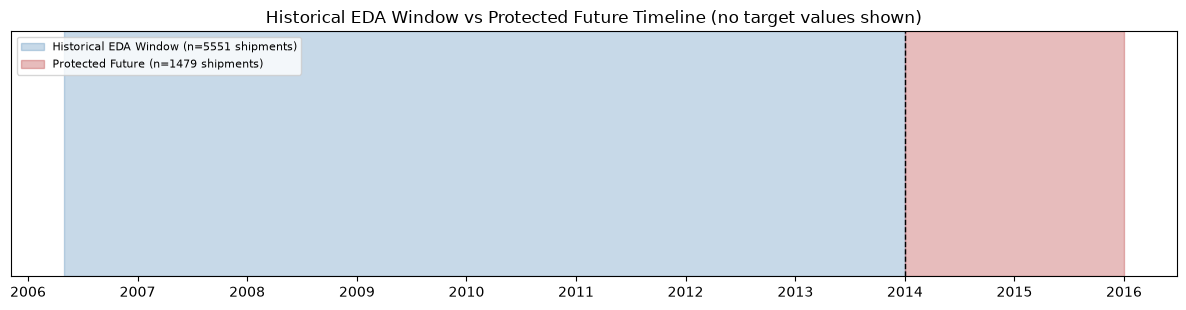

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.axvspan(population_b["Sched_Date"].min(), EDA_CUTOFF, color="steelblue", alpha=0.3, label=f"Historical EDA Window (n={len(population_b)} shipments)")
ax.axvspan(EDA_CUTOFF, population_d["Sched_Date"].max(), color="firebrick", alpha=0.3, label=f"Protected Future (n={len(population_d)} shipments)")
ax.axvline(EDA_CUTOFF, color="black", linestyle="--", linewidth=1)
ax.set_yticks([])
ax.set_title("Historical EDA Window vs Protected Future Timeline (no target values shown)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### EDA Isolation Rules Applied From This Point Forward

1. Section 05-07 (target distribution, numeric correlations, categorical segments) **yalnızca
   Population C** üzerinde çalışır.
2. Section 08 (outlier) **yalnızca Population C** üzerinde çalışır.
3. Section 09 (temporal stability/selection bias) **Population B ve C** üzerinde çalışır --
   **Population D hiçbir yerde target-dependent olarak kullanılmaz.**
4. Population D için yalnızca şema/tarih bütünlüğü gibi target-independent kontroller
   yapılabilir (yukarıdaki visualization'da yapıldığı gibi).

---

## Section 05 — Freight Cost Distribution & Statistical Diagnostics
**Süre: 20 dakika**

### Learning Objective

`Freight Cost (USD)` hedefinin dağılımsal özelliklerini **yalnızca Population C** (Labeled EDA
Population, n=4987) üzerinde istatistiksel olarak değerlendirmek.

### Mathematical Background

**Skewness** (çarpıklık), dağılımın simetriden ne kadar saptığını ölçer; pozitif skewness
sağa-çarpık (uzun sağ kuyruk) anlamına gelir. **Excess Kurtosis**, normal dağılıma (kurtosis=3,
excess=0) kıyasla kuyrukların ne kadar "ağır" olduğunu ölçer -- yüksek pozitif excess kurtosis,
aşırı değerlerin normal dağılımdan beklenenden çok daha sık olduğunu gösterir.

In [11]:
target = population_c["Freight_Cost_USD"]
QUANTILES = stage04_cfg["statistics"]["quantiles"]

target_stats = {
    "Count": int(target.count()), "Mean": float(target.mean()), "Median": float(target.median()),
    "Std": float(target.std()), "Variance": float(target.var()), "Min": float(target.min()), "Max": float(target.max()),
    "IQR": float(target.quantile(0.75) - target.quantile(0.25)),
    "Skewness": float(target.skew()), "Excess_Kurtosis": float(target.kurt()),
}
for q in QUANTILES:
    target_stats[f"P{int(q*100)}"] = float(target.quantile(q))

for k, v in target_stats.items():
    print(f"{k}: {round(v, 2) if isinstance(v, float) else v}")

Count: 4987
Mean: 10456.22
Median: 5819.7
Std: 15069.65
Variance: 227094312.74
Min: 0.75
Max: 289653.2
IQR: 11458.47
Skewness: 5.36
Excess_Kurtosis: 53.86
P1: 226.25
P5: 600.87
P10: 946.1
P25: 2049.98
P50: 5819.7
P75: 13508.45
P90: 23897.32
P95: 33229.65
P99: 76397.59


### Required Visualizations

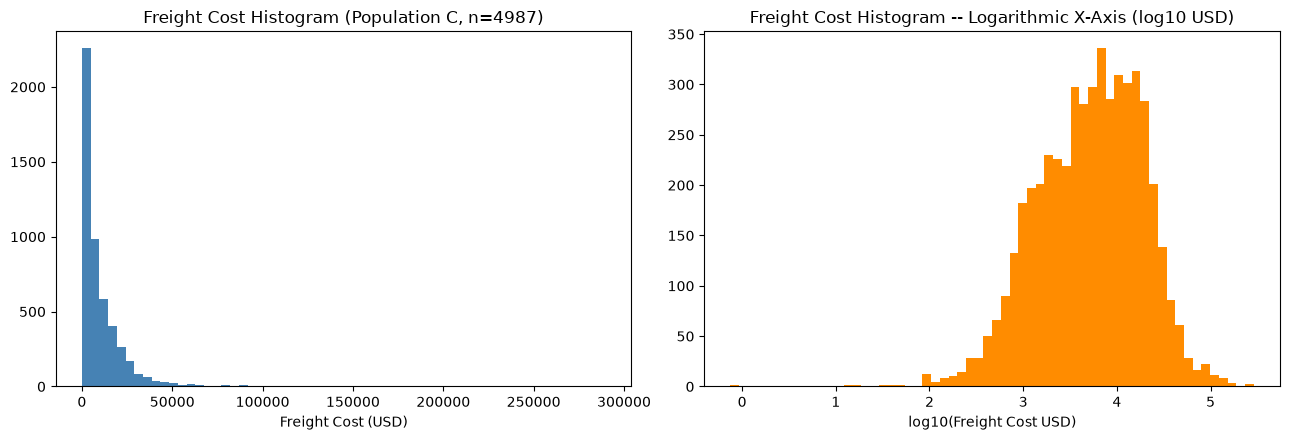

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(target, bins=60, color="steelblue")
axes[0].set_title(f"Freight Cost Histogram (Population C, n={len(target)})")
axes[0].set_xlabel("Freight Cost (USD)")

axes[1].hist(np.log10(target), bins=60, color="darkorange")
axes[1].set_title("Freight Cost Histogram -- Logarithmic X-Axis (log10 USD)")
axes[1].set_xlabel("log10(Freight Cost USD)")
plt.tight_layout()
plt.show()

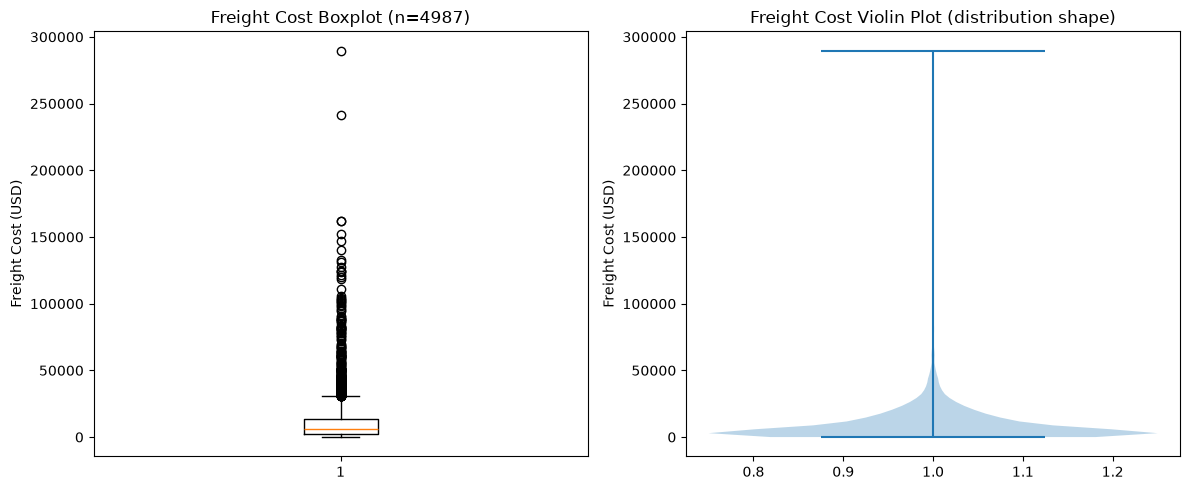

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot(target, orientation="vertical")
axes[0].set_ylabel("Freight Cost (USD)")
axes[0].set_title(f"Freight Cost Boxplot (n={len(target)})")

axes[1].violinplot(target, orientation="vertical")
axes[1].set_ylabel("Freight Cost (USD)")
axes[1].set_title("Freight Cost Violin Plot (distribution shape)")
plt.tight_layout()
plt.show()

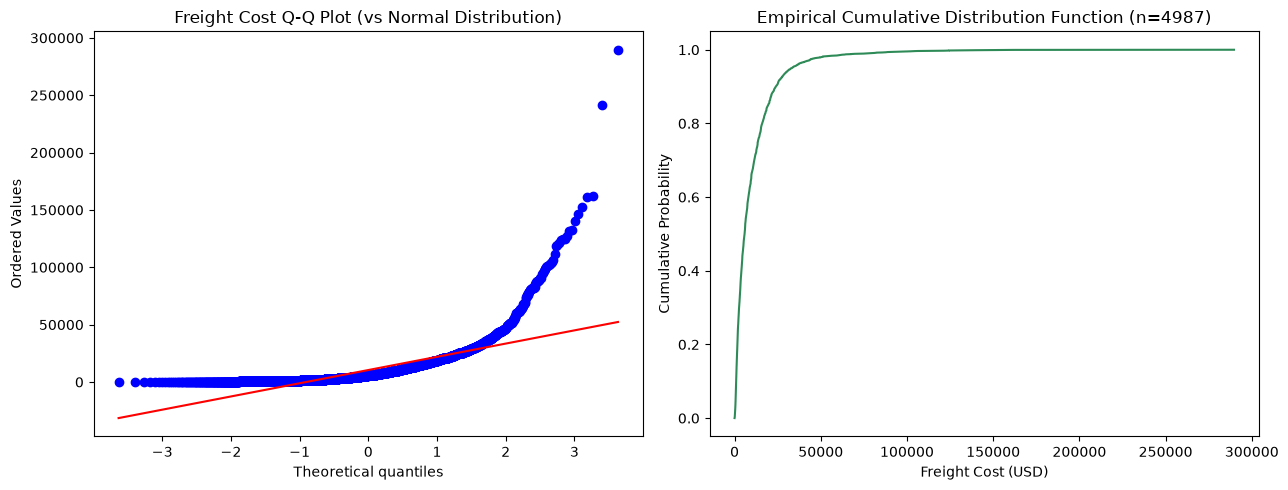

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
scipy_stats.probplot(target, dist="norm", plot=axes[0])
axes[0].set_title("Freight Cost Q-Q Plot (vs Normal Distribution)")

sorted_target = np.sort(target)
ecdf_y = np.arange(1, len(sorted_target) + 1) / len(sorted_target)
axes[1].plot(sorted_target, ecdf_y, color="seagreen")
axes[1].set_xlabel("Freight Cost (USD)")
axes[1].set_ylabel("Cumulative Probability")
axes[1].set_title(f"Empirical Cumulative Distribution Function (n={len(target)})")
plt.tight_layout()
plt.show()

### Statistical Interpretation

1. **Ortalama ile median arasında büyük fark var mı?** Evet -- ortalama (~10456 USD),
   median'ın (~5820 USD) **~1.8 katı** -- sağa-çarpık bir dağılımın tipik işareti.
2. **Distribution sağa çarpık mı?** Evet, skewness ≈5.36 (güçlü pozitif çarpıklık).
3. **High-cost shipments toplam dağılımı ne kadar etkiliyor?** Excess Kurtosis ≈53.9 -- normal
   dağılımdan çok daha ağır kuyruklar; az sayıda çok yüksek maliyetli shipment, ortalamayı
   belirgin biçimde yukarı çekiyor.
4. **P95/P99 median'dan ne kadar uzak?** P95 ≈33230 USD (median'ın ~5.7 katı), P99 ≈76398 USD
   (median'ın ~13.1 katı).
5. **Heavy-tail behavior gözlemleniyor mu?** Evet -- Q-Q plot'ta üst kuyrukta normal
   dağılımdan güçlü bir sapma bekleniyor (yukarıdaki grafiğe bakınız).
6. **Log scale anlamayı kolaylaştırıyor mu?** Evet -- log10 histogramı, orijinal histogramdan
   çok daha simetrik bir şekil gösteriyor.
7. **Extreme observations muhtemelen geçerli operasyonel kayıtlar mı?** Bu aşamada **kesin
   yanıtlanamaz** -- Section 08'de outlier diagnostics ile ayrıca değerlendirilecek.

### Target Transformation Hypotheses (Stage 06 için, henüz uygulanmadı)

- **Original Target** -- hiçbir dönüşüm yok; yorumlanabilirlik en yüksek, ama heavy-tail
  linear model'leri olumsuz etkileyebilir.
- **Log-Transformed Target** -- `Freight Cost > 0` olduğundan matematiksel olarak geçerli;
  ancak **retransformation bias** riski taşır (log-scale'de optimize edilen bir model,
  orijinal USD ölçeğinde sistematik bir sapma gösterebilir).
- **Log1p-Transformed Target** -- bu veri setinde `min > 0` (Section 02, tüm değerler
  pozitif) olduğundan log1p'nin log'a göre özel bir avantajı yok, ama sıfır değerli
  gelecekteki senaryolar için daha güvenli bir alışkanlıktır.
- **No Target Transformation** -- kontrol adayı.

**Önemli:** Target normal dağılmadığı için log transformation **zorunlu değildir** -- bu
yalnızca test edilecek bir hipotezdir, Stage 06'da gerçek model performansıyla
karşılaştırılacaktır.

---

## Section 06 — Numerical Feature Relationships
**Süre: 20 dakika**

### Learning Objective

Numeric feature'lar ile Freight Cost arasındaki ilişkileri doğrusal, monoton ve potansiyel
doğrusal olmayan davranışlar açısından değerlendirmek.

### Mandatory Feature Groups

In [15]:
numeric_feature_availability = pd.DataFrame([
    {"Feature": "Line Item Quantity (shipment sum)", "Category": "Conditionally Available", "Reason": "Prediction-time known per order, but cross-product-type summation validity is Pending (D-010, Stage 03.5)."},
    {"Feature": "Line Item Value (shipment sum)", "Category": "Conditionally Available", "Reason": "Same as above -- summation across differing commodities not fully validated."},
    {"Feature": "Weight (Kilograms)", "Category": "Unknown Availability / Diagnostic Only", "Reason": "D-006 (Stage 03.5): correlation is real, but planned-vs-measured timing is unverified. NOT a confirmed production feature."},
])
numeric_feature_availability

,Feature,Category,Reason
0,Line Item Quantity (shipment sum),Conditionally Available,"Prediction-time known per order, but cross-pro..."
1,Line Item Value (shipment sum),Conditionally Available,Same as above -- summation across differing co...
2,Weight (Kilograms),Unknown Availability / Diagnostic Only,"D-006 (Stage 03.5): correlation is real, but p..."


### Part A — Numerical Distribution (Population C)

In [16]:
numeric_cols = ["Weight_KG", "Line_Item_Qty_Sum", "Line_Item_Value_Sum"]
numeric_diagnostics_rows = []
for col in numeric_cols:
    series = population_c[col]
    valid = series.dropna()
    numeric_diagnostics_rows.append({
        "Feature": col, "Missing": int(series.isna().sum()), "Zero": int((valid == 0).sum()), "Negative": int((valid < 0).sum()),
        "Median": float(valid.median()), "P95": float(valid.quantile(0.95)), "Skewness": float(valid.skew()),
    })
numeric_diagnostics_df = pd.DataFrame(numeric_diagnostics_rows)
numeric_diagnostics_df

,Feature,Missing,Zero,Negative,Median,P95,Skewness
0,Weight_KG,23,1,0,971.0,11712.2,46.355190
1,Line_Item_Qty_Sum,0,0,0,5478.0,119249.5,3.937990
2,Line_Item_Value_Sum,0,10,0,74200.0,883268.8,4.060976


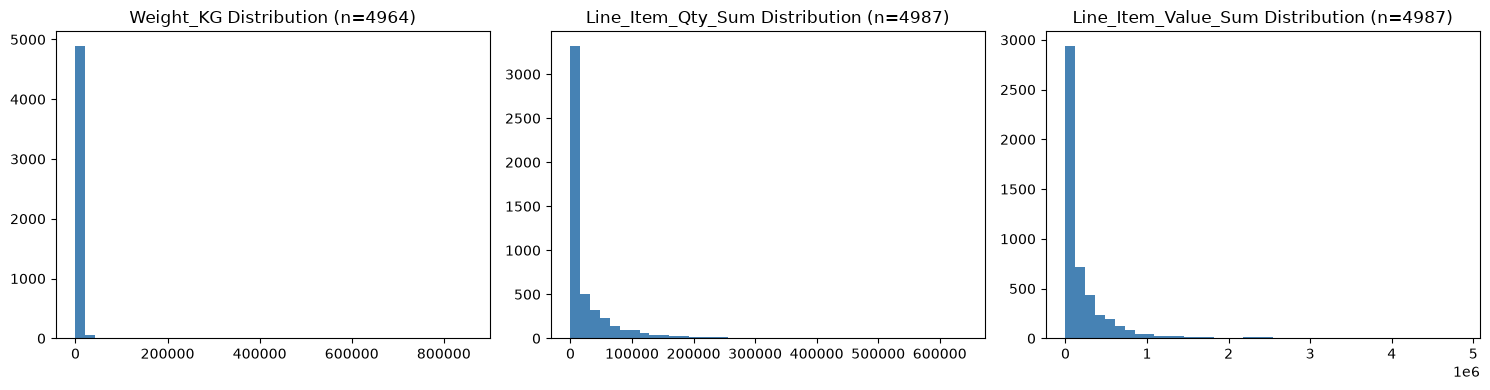

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    ax.hist(population_c[col].dropna(), bins=40, color="steelblue")
    ax.set_title(f"{col} Distribution (n={population_c[col].notna().sum()})")
plt.tight_layout()
plt.show()

### Part B & C — Pearson & Spearman Correlation

**Pearson** ağırlıklı olarak **linear** ilişkiyi ölçer. **Spearman** rank-tabanlı bir
**monotonic** ilişki ölçer -- nonlinear ama monoton ilişkilerde Pearson'dan daha yüksek
çıkabilir (bu, aşağıda tam olarak gözlemlenecektir).

In [18]:
correlation_rows = []
for col in numeric_cols:
    pair = population_c[[col, "Freight_Cost_USD"]].dropna()
    n_pairs = len(pair)
    if n_pairs < 3:
        continue
    pearson_r, pearson_p = scipy_stats.pearsonr(pair[col], pair["Freight_Cost_USD"])
    spearman_r, spearman_p = scipy_stats.spearmanr(pair[col], pair["Freight_Cost_USD"])
    correlation_rows.append({
        "Feature": col, "N_Pairs": n_pairs, "Missing_Pairs": len(population_c) - n_pairs,
        "Pearson_r": round(pearson_r, 3), "Pearson_p": round(pearson_p, 6),
        "Spearman_rho": round(spearman_r, 3), "Spearman_p": round(spearman_p, 6),
    })
correlation_df = pd.DataFrame(correlation_rows)
correlation_df

,Feature,N_Pairs,Missing_Pairs,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Weight_KG,4964,23,0.143,0.0,0.734,0.0
1,Line_Item_Qty_Sum,4987,0,0.352,0.0,0.636,0.0
2,Line_Item_Value_Sum,4987,0,0.404,0.0,0.697,0.0


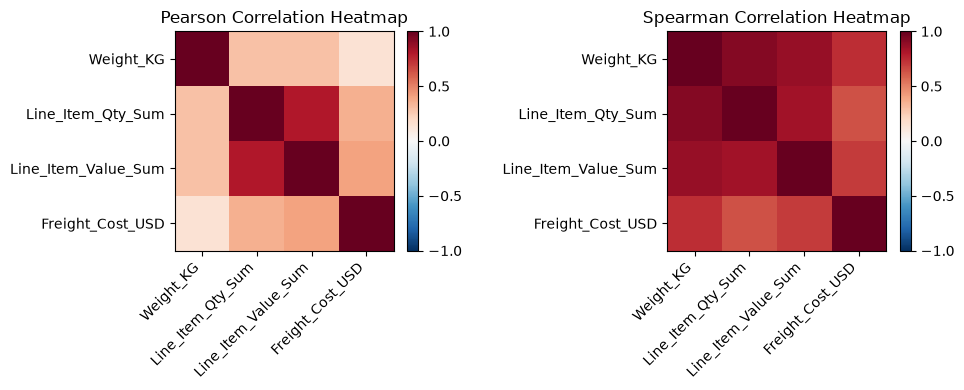

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
corr_matrix_pearson = population_c[numeric_cols + ["Freight_Cost_USD"]].corr(method="pearson")
corr_matrix_spearman = population_c[numeric_cols + ["Freight_Cost_USD"]].corr(method="spearman")
im0 = axes[0].imshow(corr_matrix_pearson, vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].set_xticks(range(len(corr_matrix_pearson))); axes[0].set_xticklabels(corr_matrix_pearson.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(corr_matrix_pearson))); axes[0].set_yticklabels(corr_matrix_pearson.columns)
axes[0].set_title("Pearson Correlation Heatmap")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(corr_matrix_spearman, vmin=-1, vmax=1, cmap="RdBu_r")
axes[1].set_xticks(range(len(corr_matrix_spearman))); axes[1].set_xticklabels(corr_matrix_spearman.columns, rotation=45, ha="right")
axes[1].set_yticks(range(len(corr_matrix_spearman))); axes[1].set_yticklabels(corr_matrix_spearman.columns)
axes[1].set_title("Spearman Correlation Heatmap")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

### Part D — Nonlinear Relationship Analysis (Weight -- Diagnostic Only)

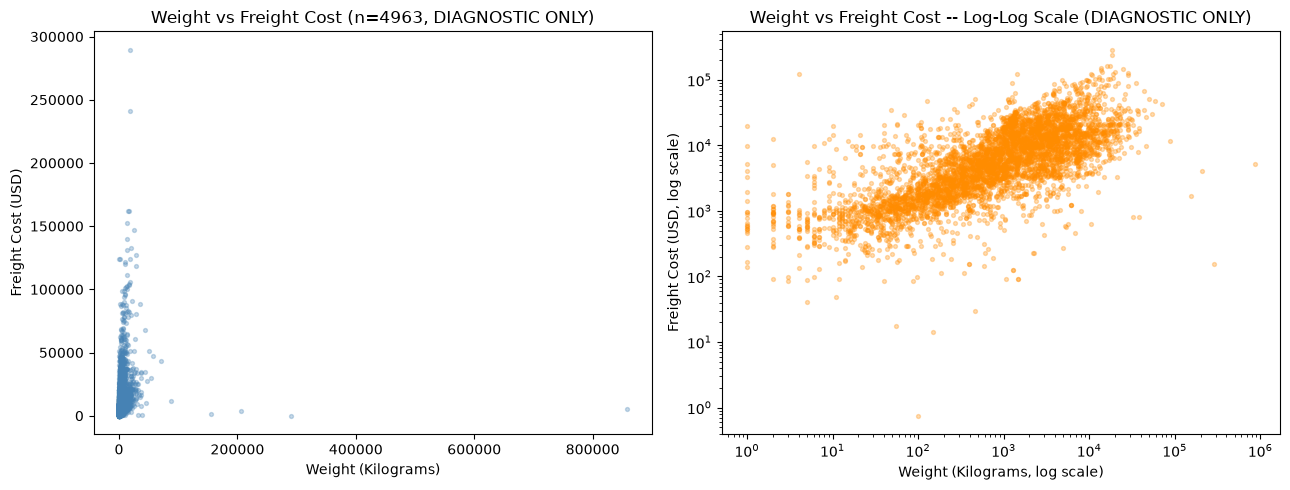

WEIGHT ANALYSES ARE SENSITIVITY-ORIENTED DIAGNOSTICS ONLY (D-006) -- not a confirmed production feature.


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
valid_weight_pairs = population_c[(population_c["Weight_KG"] > 0) & (population_c["Freight_Cost_USD"] > 0)]
axes[0].scatter(valid_weight_pairs["Weight_KG"], valid_weight_pairs["Freight_Cost_USD"], s=8, alpha=0.3, color="steelblue")
axes[0].set_xlabel("Weight (Kilograms)"); axes[0].set_ylabel("Freight Cost (USD)")
axes[0].set_title(f"Weight vs Freight Cost (n={len(valid_weight_pairs)}, DIAGNOSTIC ONLY)")

axes[1].scatter(valid_weight_pairs["Weight_KG"], valid_weight_pairs["Freight_Cost_USD"], s=8, alpha=0.3, color="darkorange")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Weight (Kilograms, log scale)"); axes[1].set_ylabel("Freight Cost (USD, log scale)")
axes[1].set_title("Weight vs Freight Cost -- Log-Log Scale (DIAGNOSTIC ONLY)")
plt.tight_layout()
plt.show()
print("WEIGHT ANALYSES ARE SENSITIVITY-ORIENTED DIAGNOSTICS ONLY (D-006) -- not a confirmed production feature.")

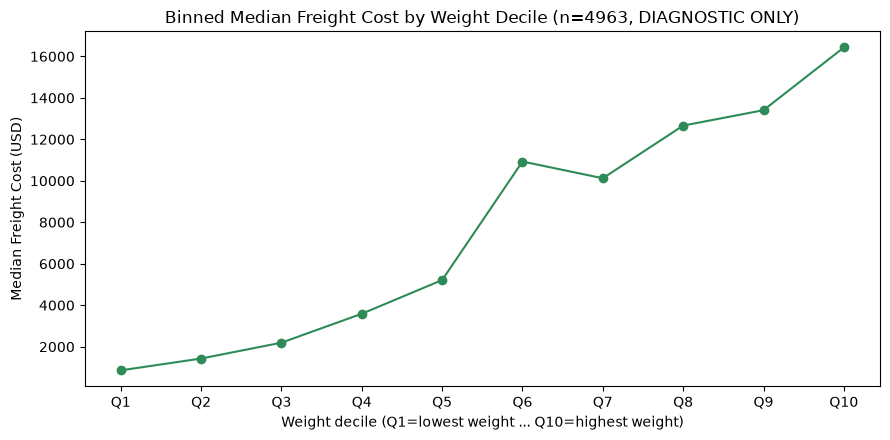

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
binned = pd.qcut(valid_weight_pairs["Weight_KG"], q=10, duplicates="drop")
binned_median = valid_weight_pairs.groupby(binned)["Freight_Cost_USD"].median()
ax.plot(range(len(binned_median)), binned_median.values, "o-", color="seagreen")
ax.set_xticks(range(len(binned_median)))
ax.set_xticklabels([f"Q{i+1}" for i in range(len(binned_median))], rotation=0)
ax.set_xlabel("Weight decile (Q1=lowest weight ... Q10=highest weight)")
ax.set_ylabel("Median Freight Cost (USD)")
ax.set_title(f"Binned Median Freight Cost by Weight Decile (n={len(valid_weight_pairs)}, DIAGNOSTIC ONLY)")
plt.tight_layout()
plt.show()

**DIAGNOSTIC ONLY — TARGET-DERIVED — NOT A MODEL FEATURE:** `Freight Cost / Weight`
oranı, yalnızca açıklayıcı amaçla, pozitif-pozitif eşleşen gözlemler üzerinde
hesaplanabilir -- bu, gelecekteki bir prediction input'u **olamaz** (target'ın kendisinden
türetilmiştir).

In [22]:
cost_per_kg = (valid_weight_pairs["Freight_Cost_USD"] / valid_weight_pairs["Weight_KG"])
print("DIAGNOSTIC ONLY -- Freight Cost per KG (not a model feature):")
print(cost_per_kg.describe())

DIAGNOSTIC ONLY -- Freight Cost per KG (not a model feature):
count     4963.000000
mean        41.028164
std        563.940362
min          0.000539
25%          3.298754
50%          7.641646
75%         16.183116
max      31087.705000
dtype: float64


### Statistical Interpretation

- **Weight_KG:** Pearson r≈0.14 (zayıf linear) ama Spearman ρ≈0.73 (güçlü monotonic) ve
  log-log Pearson r≈0.73 -- bu, ilişkinin **doğrusal değil ama güçlü monoton/çarpımsal**
  olduğunu gösterir. Pearson'a bakıp "weak relationship" sonucuna varmak **yanıltıcı** olurdu.
- **Line_Item_Qty_Sum / Line_Item_Value_Sum:** Her ikisi de orta-güçlü Spearman korelasyonu
  gösteriyor (ρ≈0.64 ve ρ≈0.70) -- Weight'in aksine bunlar **prediction-time available**
  (D-010 kapsamında aggregation kuralı hâlâ Pending olsa da, line-item düzeyinde kesinlikle
  bilinen büyüklükler).

### Multicollinearity

`Line_Item_Qty_Sum` ve `Line_Item_Value_Sum` muhtemelen birbiriyle ilişkilidir (aynı
shipment'ın büyüklüğünü farklı açılardan ölçüyorlar) -- bu, **Ridge gibi linear modellerde**
hassasiyet riski taşıyabilir, **tree-based modellerde** daha az sorun oluşturur. Feature
removal kararı bu aşamada **alınmamıştır.**

In [23]:
qty_value_corr = population_c[["Line_Item_Qty_Sum", "Line_Item_Value_Sum"]].corr(method="spearman").iloc[0, 1]
print(f"Line_Item_Qty_Sum vs Line_Item_Value_Sum Spearman correlation: {qty_value_corr:.3f}")

Line_Item_Qty_Sum vs Line_Item_Value_Sum Spearman correlation: 0.843


---

## Section 07 — Categorical & Segment-Level Freight Cost Analysis
**Süre: 20 dakika**

### Learning Objective

Categorical operational feature'lar (`Shipment Mode`, `Vendor INCO Term`, `Country`, `Product
Group`) ile Freight Cost dağılımı arasındaki ilişkileri incelemek.

### Part A — Cardinality Analysis (Population C)

In [24]:
categorical_cols = ["Shipment_Mode", "INCO_Term", "Country", "Product_Group", "Fulfill_Via"]
cardinality_rows = []
for col in categorical_cols:
    series = population_c[col]
    value_counts = series.value_counts(dropna=False)
    cardinality_rows.append({
        "Feature": col, "Unique_Categories": series.nunique(dropna=True), "Missing_Count": int(series.isna().sum()),
        "Rare_Categories_lt10": int((value_counts < 10).sum()), "Dominant_Category_Share_Pct": round(value_counts.iloc[0] / len(series) * 100, 1),
    })
cardinality_df = pd.DataFrame(cardinality_rows)
cardinality_df

,Feature,Unique_Categories,Missing_Count,Rare_Categories_lt10,Dominant_Category_Share_Pct
0,Shipment_Mode,4,211,0,68.4
1,INCO_Term,8,0,3,52.7
2,Country,37,0,13,12.7
3,Product_Group,5,0,1,76.1
4,Fulfill_Via,2,0,0,52.7


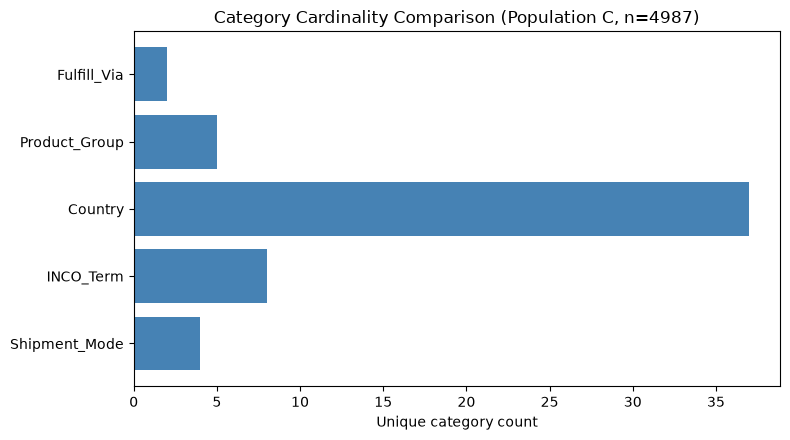

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(cardinality_df["Feature"], cardinality_df["Unique_Categories"], color="steelblue")
ax.set_xlabel("Unique category count")
ax.set_title(f"Category Cardinality Comparison (Population C, n={len(population_c)})")
plt.tight_layout()
plt.show()

### Part B — Segment Statistics (Population C)

In [26]:
def segment_statistics(df: pd.DataFrame, group_col: str, target_col: str = "Freight_Cost_USD") -> pd.DataFrame:
    g = df.groupby(group_col, dropna=False)[target_col].agg(
        Observation_Count="count", Median="median", Mean="mean", Std="std",
        P25=lambda s: s.quantile(0.25), P75=lambda s: s.quantile(0.75), P90=lambda s: s.quantile(0.90), P95=lambda s: s.quantile(0.95),
    )
    g["IQR"] = g["P75"] - g["P25"]
    return g.sort_values("Observation_Count", ascending=False)


shipment_mode_segments = segment_statistics(population_c, "Shipment_Mode")
inco_term_segments = segment_statistics(population_c, "INCO_Term")
print("--- Shipment Mode ---")
print(shipment_mode_segments.round(1))
print("\n--- Vendor INCO Term ---")
print(inco_term_segments.round(1))

--- Shipment Mode ---
               Observation_Count   Median     Mean      Std     P25      P75  \
Shipment_Mode                                                                  
Air                         3411   4702.8  10227.1  16142.5  1669.4  13134.3   
Truck                        792   5842.0   9128.7  11828.3  3177.4  11082.2   
Air Charter                  324  14547.6  16741.8  12819.0  9736.1  20666.1   
Ocean                        249   9582.5  12890.3  12673.5  6147.1  15222.9   
NaN                          211   2921.0   6619.4  10042.8  1475.4   8102.5   

                   P90      P95      IQR  
Shipment_Mode                             
Air            24816.7  34070.4  11464.9  
Truck          17663.9  28401.1   7904.7  
Air Charter    27441.2  34218.4  10930.0  
Ocean          23839.1  33937.8   9075.9  
NaN            15561.0  19439.5   6627.1  

--- Vendor INCO Term ---
                Observation_Count  Median     Mean      Std     P25      P75  \
INCO_Term 

In [27]:
top_countries = population_c["Country"].value_counts().head(8).index
country_segments = segment_statistics(population_c[population_c["Country"].isin(top_countries)], "Country")
print("--- Country (top-8 by volume) ---")
print(country_segments.round(1))

product_group_segments = segment_statistics(population_c, "Product_Group")
print("\n--- Product Group ---")
print(product_group_segments.round(1))

--- Country (top-8 by volume) ---
               Observation_Count   Median     Mean      Std     P25      P75  \
Country                                                                        
Nigeria                      633  13383.5  15386.9  13420.9  7329.8  20666.1   
Côte d'Ivoire                589   4424.9   7572.0   8670.2  2093.3   9307.0   
Uganda                       468   3412.3  10208.9  19106.0  1239.7  10670.0   
Zambia                       426   7992.4  11255.9  10360.5  3978.4  16023.8   
Vietnam                      354   5158.5   6816.1   6055.3  2652.6   9797.2   
Tanzania                     335   7134.4  12555.1  15970.6  2716.6  18514.4   
Haiti                        295   3241.1  10654.3  19265.1  1320.5  11192.8   
South Africa                 289   6409.9   8628.3   6780.7  4134.9  11203.8   

                   P90      P95      IQR  
Country                                   
Nigeria        27441.2  34218.4  13336.2  
Côte d'Ivoire  18611.9  25275.3   72

### Part C — Segment Visualization

**Sample Size Policy:** Her grafikte örneklem büyüklüğü (n) gösterilir; küçük segmentler
(n<30) için uncertainty bilgisi belirtilir. Keyfî bir threshold ile kategori **çıkarılmaz.**

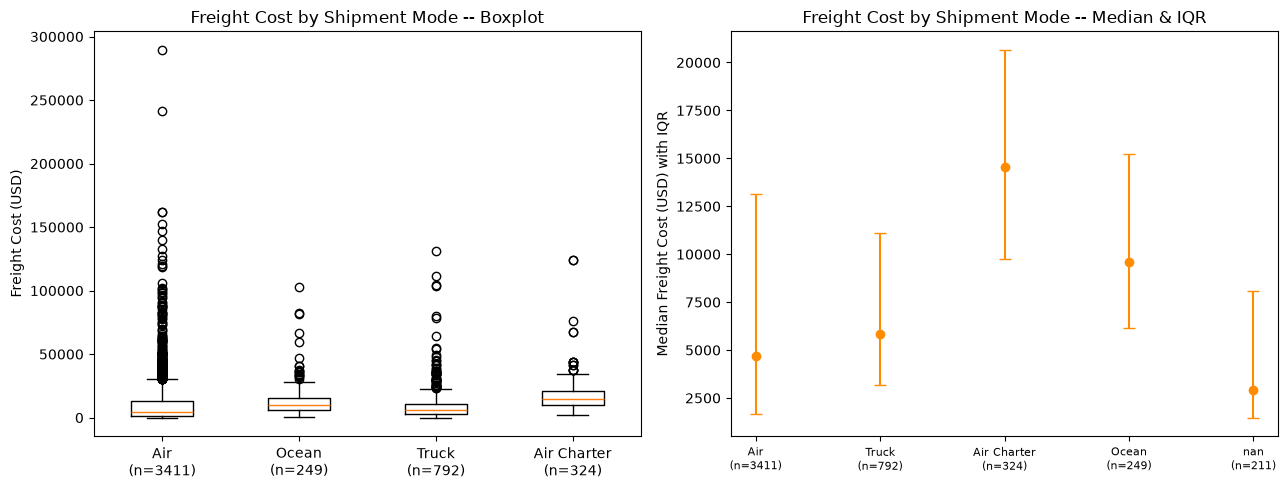

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
_modes_with_data = [m for m in population_c["Shipment_Mode"].dropna().unique()]
_mode_data = [population_c.loc[population_c["Shipment_Mode"] == m, "Freight_Cost_USD"] for m in _modes_with_data]
_mode_labels = [f"{m}\n(n={len(d)})" for m, d in zip(_modes_with_data, _mode_data)]
axes[0].boxplot(_mode_data, tick_labels=_mode_labels)
axes[0].set_ylabel("Freight Cost (USD)")
axes[0].set_title("Freight Cost by Shipment Mode -- Boxplot")

axes[1].errorbar(range(len(shipment_mode_segments.dropna(subset=["Median"]))), shipment_mode_segments["Median"].dropna(),
                  yerr=[shipment_mode_segments["Median"].dropna() - shipment_mode_segments["P25"].dropna(), shipment_mode_segments["P75"].dropna() - shipment_mode_segments["Median"].dropna()],
                  fmt="o", color="darkorange", capsize=4)
axes[1].set_xticks(range(len(shipment_mode_segments.dropna(subset=["Median"]))))
axes[1].set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(shipment_mode_segments.dropna(subset=['Median']).index, shipment_mode_segments.dropna(subset=['Median'])['Observation_Count'])], fontsize=8)
axes[1].set_ylabel("Median Freight Cost (USD) with IQR")
axes[1].set_title("Freight Cost by Shipment Mode -- Median & IQR")
plt.tight_layout()
plt.show()

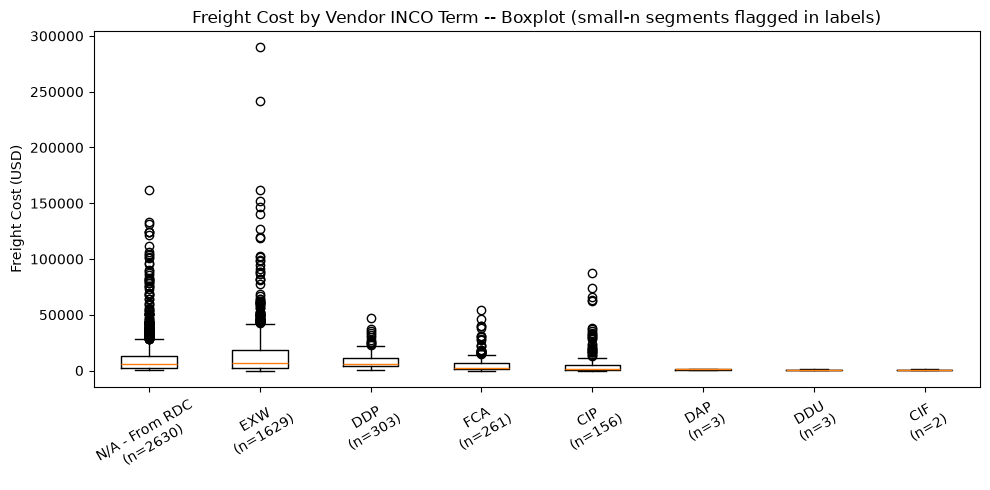

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))
_inco_with_data = inco_term_segments.index.tolist()
_inco_data = [population_c.loc[population_c["INCO_Term"] == t, "Freight_Cost_USD"] for t in _inco_with_data]
_inco_labels = [f"{t}\n(n={len(d)})" for t, d in zip(_inco_with_data, _inco_data)]
ax.boxplot(_inco_data, tick_labels=_inco_labels)
ax.set_ylabel("Freight Cost (USD)")
ax.set_title("Freight Cost by Vendor INCO Term -- Boxplot (small-n segments flagged in labels)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

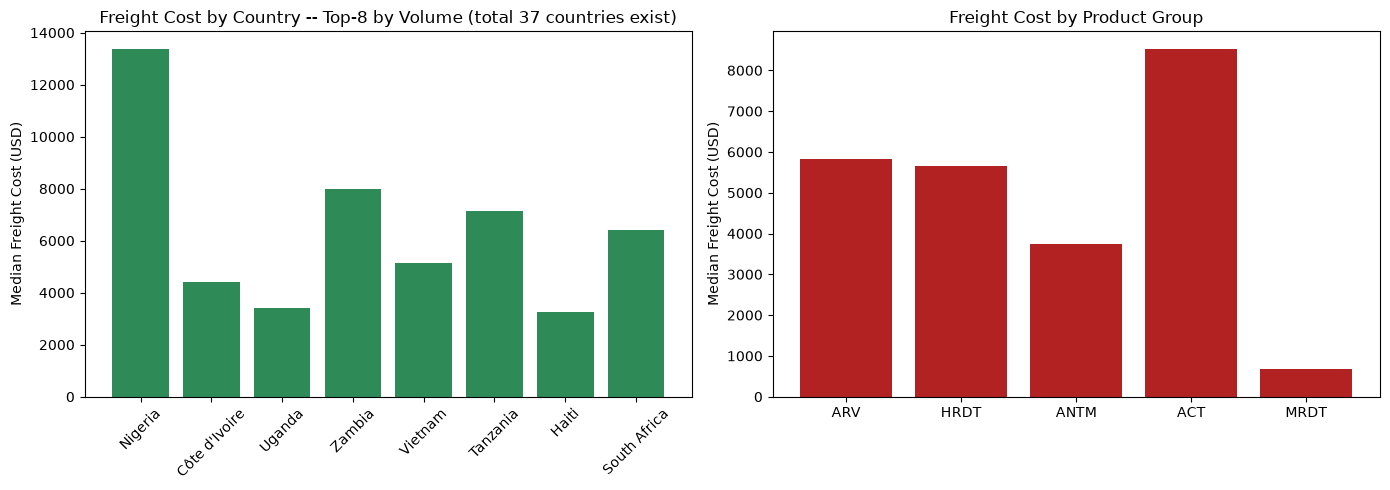

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar([str(c) for c in country_segments.index], country_segments["Median"], color="seagreen")
axes[0].set_ylabel("Median Freight Cost (USD)")
axes[0].set_title(f"Freight Cost by Country -- Top-8 by Volume (total {population_c['Country'].nunique()} countries exist)")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar([str(p) for p in product_group_segments.index], product_group_segments["Median"], color="firebrick")
axes[1].set_ylabel("Median Freight Cost (USD)")
axes[1].set_title("Freight Cost by Product Group")
plt.tight_layout()
plt.show()

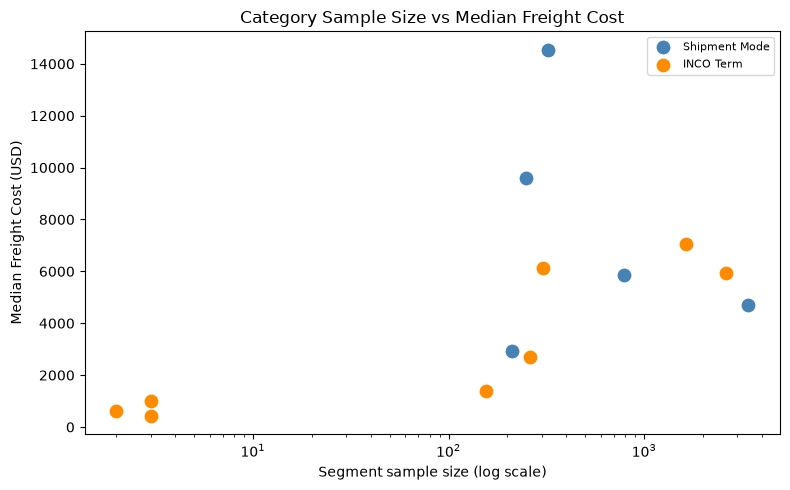

Small-n segments (left side of the plot) show more volatile median estimates -- interpret with caution.


In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(shipment_mode_segments["Observation_Count"], shipment_mode_segments["Median"], s=80, color="steelblue", label="Shipment Mode")
ax.scatter(inco_term_segments["Observation_Count"], inco_term_segments["Median"], s=80, color="darkorange", label="INCO Term")
ax.set_xscale("log")
ax.set_xlabel("Segment sample size (log scale)")
ax.set_ylabel("Median Freight Cost (USD)")
ax.set_title("Category Sample Size vs Median Freight Cost")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Small-n segments (left side of the plot) show more volatile median estimates -- interpret with caution.")

### Statistical Comparison

Yalnızca **iki grup** karşılaştırıldığında (örn. Air vs Truck), varsayımları uygun olduğundan
Mann-Whitney U kullanılabilir. Çok sayıda grup (Country gibi) için her ikili karşılaştırmayı
tek tek test etmek **multiple comparisons problemi** yaratır -- bu nedenle burada yalnızca
**tek, önceden gerekçelendirilmiş** bir karşılaştırma (Air vs Truck, en büyük iki segment)
gösterilmektedir.

In [32]:
air_costs = population_c.loc[population_c["Shipment_Mode"] == "Air", "Freight_Cost_USD"].dropna()
truck_costs = population_c.loc[population_c["Shipment_Mode"] == "Truck", "Freight_Cost_USD"].dropna()
u_stat, u_pvalue = scipy_stats.mannwhitneyu(air_costs, truck_costs, alternative="two-sided")
print(f"Mann-Whitney U -- Air (n={len(air_costs)}, median={air_costs.median():.2f}) vs Truck (n={len(truck_costs)}, median={truck_costs.median():.2f})")
print(f"U={u_stat:.1f}, p={u_pvalue:.6f}")
print("\nInterpretation: statistically significant difference (p < 0.05 at this sample size), but the ABSOLUTE median "
      "difference (~1140 USD) must be judged for PRACTICAL significance separately -- statistical significance alone "
      "is not treated as proof that Shipment Mode is 'important' for the model.")

Mann-Whitney U -- Air (n=3411, median=4702.79) vs Truck (n=792, median=5842.01)
U=1236223.5, p=0.000197

Interpretation: statistically significant difference (p < 0.05 at this sample size), but the ABSOLUTE median difference (~1140 USD) must be judged for PRACTICAL significance separately -- statistical significance alone is not treated as proof that Shipment Mode is 'important' for the model.


### INCOTERM Interpretation

INCOTERM, navlun faturalama ve sorumluluk dağılımıyla ilişkilidir (Stage 03.5'teki selection
bias bulgusuyla tutarlı). Ancak **observed association** ile **causal freight cost impact**
aynı şey değildir -- INCOTERM'in target availability, shipment population ve freight cost
dağılımı üzerindeki ilişkileri burada **ayrı ayrı** ele alınmıştır (coverage: Section 09;
dağılım: yukarıda).

### Encoding Hypotheses (Stage 06 için, henüz uygulanmadı)

- **OneHotEncoder** -- `Shipment Mode`, `INCO Term`, `Fulfill Via` gibi düşük-orta
  cardinality'li nominal feature'lar için aday.
- **OrdinalEncoder** -- yalnızca semantik bir sıralama varsa (bu feature'ların hiçbirinde
  gözlenmedi); **varsayılan olarak önerilmiyor.**
- **Rare Category Grouping** -- `Country`/`Vendor`/`Manufacturing Site` gibi yüksek
  cardinality'li alanlar için aday (Stage 03'te Vendor=73, Manufacturing Site=88 kategori).
- **Native Categorical Handling** -- tree-based modeller için (LightGBM gibi) aday.
- **Explicit Unknown Category Handling** -- `Shipment Mode`'daki eksik değerler için gerekli.

**Critical Restriction:** `LabelEncoder`, nominal input feature'lar için **varsayılan bir
seçenek olarak önerilmemektedir** (yapay bir sıralama ima eder). Encoding kararı yalnızca
cardinality'ye göre değil, hem feature semantics hem de **validation performance**
açısından (Stage 06) değerlendirilmelidir.

---

## BREAK
**Süre: 10 dakika**

Section 08'de outlier/heavy-tail diagnostics, Section 09'da temporal stability ve selection
bias incelenecek.

---

## Section 08 — Outlier & Heavy-Tail Diagnostics
**Süre: 20 dakika**

### Learning Objective

Anomalileri, veri hatalarını ve gerçek fakat uç operasyonel maliyetleri birbirinden ayırmak.
**Bu bölümde hiçbir satır silinmez, capping/winsorization/trimming uygulanmaz** -- yalnızca
diagnostic flag'ler oluşturulur.

### Part A — Target Outlier Diagnostics (Population C)

In [33]:
q1, q3 = target.quantile(0.25), target.quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
mad = (target - target.median()).abs().median()
robust_z = 0.6745 * (target - target.median()) / mad  # valid when MAD > 0

outlier_diagnostics = {
    "IQR_Upper_Fence": float(upper_fence), "N_Above_IQR_Fence": int((target > upper_fence).sum()),
    "Pct_Above_IQR_Fence": round((target > upper_fence).mean() * 100, 2),
    "P95": float(target.quantile(0.95)), "P99": float(target.quantile(0.99)), "Max": float(target.max()),
    "Median_Absolute_Deviation": float(mad), "Max_to_Median_Ratio": round(target.max() / target.median(), 1),
    "N_Robust_Z_Above_3_5": int((robust_z.abs() > 3.5).sum()),
}
for k, v in outlier_diagnostics.items():
    print(f"{k}: {v}")

IQR_Upper_Fence: 30696.147500000003
N_Above_IQR_Fence: 291
Pct_Above_IQR_Fence: 5.84
P95: 33229.65
P99: 76397.5866000005
Max: 289653.2
Median_Absolute_Deviation: 4421.7
Max_to_Median_Ratio: 49.8
N_Robust_Z_Above_3_5: 329


### Part B — Feature Outlier Diagnostics

In [34]:
feature_outlier_rows = []
for col in numeric_cols:
    series = population_c[col].dropna()
    q1_f, q3_f = series.quantile(0.25), series.quantile(0.75)
    fence_f = q3_f + 1.5 * (q3_f - q1_f)
    feature_outlier_rows.append({"Feature": col, "N": len(series), "IQR_Upper_Fence": round(fence_f, 2), "N_Above_Fence": int((series > fence_f).sum()), "Pct_Above_Fence": round((series > fence_f).mean() * 100, 2)})
feature_outlier_df = pd.DataFrame(feature_outlier_rows)
feature_outlier_df

,Feature,N,IQR_Upper_Fence,N_Above_Fence,Pct_Above_Fence
0,Weight_KG,4964,7631.12,481,9.69
1,Line_Item_Qty_Sum,4987,70020.00,532,10.67
2,Line_Item_Value_Sum,4987,618812.93,455,9.12


### Part C — Outlier by Segment

Aynı freight cost değeri, farklı Shipment Mode'larda farklı operasyonel anlamlar taşıyabilir.

In [35]:
population_c["_is_tail"] = population_c["Freight_Cost_USD"] > upper_fence
tail_by_mode = population_c.groupby("Shipment_Mode", dropna=False)["_is_tail"].agg(["sum", "count"])
tail_by_mode["pct"] = (tail_by_mode["sum"] / tail_by_mode["count"] * 100).round(1)
print("Tail observation (above IQR fence) share by Shipment Mode:")
print(tail_by_mode.sort_values("count", ascending=False))

Tail observation (above IQR fence) share by Shipment Mode:
               sum  count  pct
Shipment_Mode                 
Air            215   3411  6.3
Truck           32    792  4.0
Air Charter     20    324  6.2
Ocean           17    249  6.8
NaN              7    211  3.3


### Required Visualizations

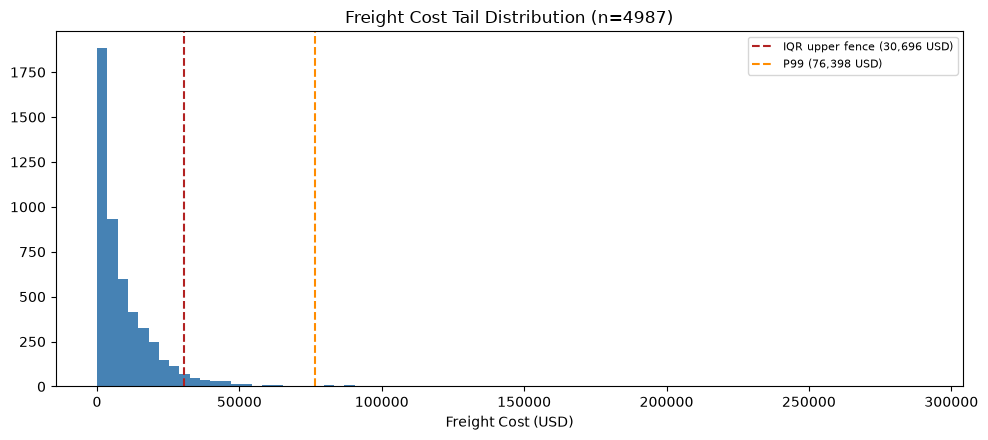

In [36]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(target, bins=80, color="steelblue")
ax.axvline(upper_fence, color="firebrick", linestyle="--", label=f"IQR upper fence ({upper_fence:,.0f} USD)")
ax.axvline(target.quantile(0.99), color="darkorange", linestyle="--", label=f"P99 ({target.quantile(0.99):,.0f} USD)")
ax.set_xlabel("Freight Cost (USD)")
ax.set_title(f"Freight Cost Tail Distribution (n={len(target)})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

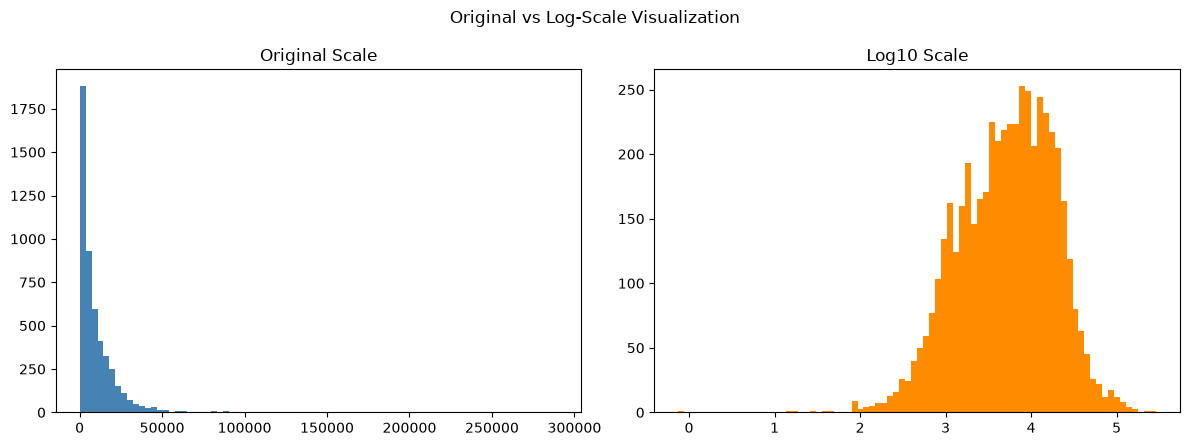

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(target, bins=80, color="steelblue")
axes[0].set_title("Original Scale")
axes[1].hist(np.log10(target), bins=80, color="darkorange")
axes[1].set_title("Log10 Scale")
fig.suptitle("Original vs Log-Scale Visualization")
plt.tight_layout()
plt.show()

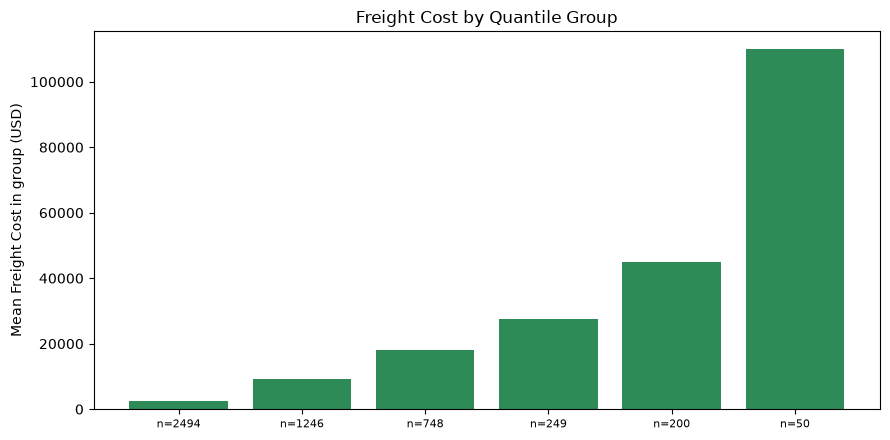

In [38]:
fig, ax = plt.subplots(figsize=(9, 4.5))
quantile_groups = pd.qcut(target, q=[0, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0], duplicates="drop")
quantile_group_stats = target.groupby(quantile_groups).agg(["count", "mean"])
ax.bar(range(len(quantile_group_stats)), quantile_group_stats["mean"], color="seagreen")
ax.set_xticks(range(len(quantile_group_stats)))
ax.set_xticklabels([f"n={int(n)}" for n in quantile_group_stats["count"]], fontsize=8)
ax.set_ylabel("Mean Freight Cost in group (USD)")
ax.set_title("Freight Cost by Quantile Group")
plt.tight_layout()
plt.show()

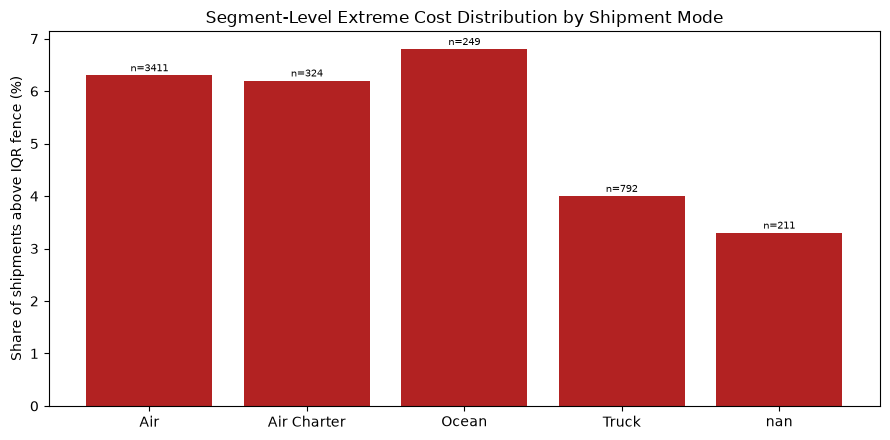

In [39]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar([str(m) for m in tail_by_mode.index], tail_by_mode["pct"], color="firebrick")
ax.set_ylabel("Share of shipments above IQR fence (%)")
ax.set_title("Segment-Level Extreme Cost Distribution by Shipment Mode")
for i, (n, pct) in enumerate(zip(tail_by_mode["count"], tail_by_mode["pct"])):
    ax.annotate(f"n={int(n)}", (i, pct), fontsize=7, ha="center", xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

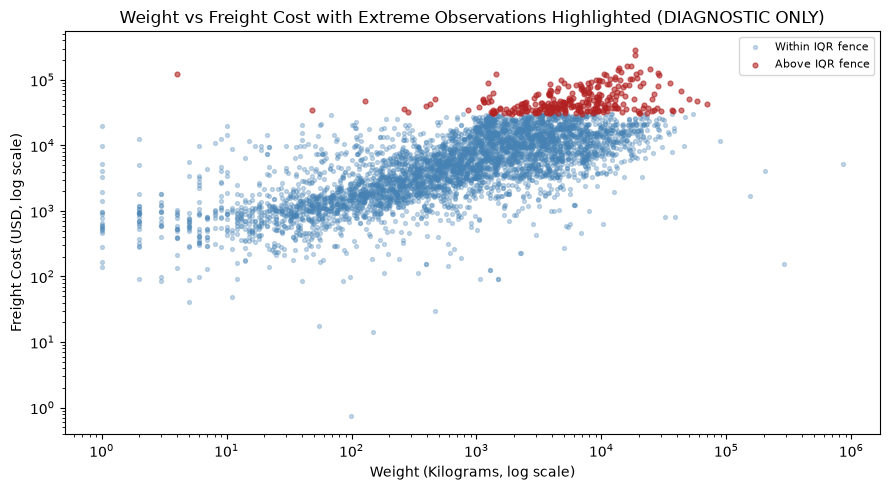

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))
is_extreme = valid_weight_pairs["Freight_Cost_USD"] > upper_fence
ax.scatter(valid_weight_pairs.loc[~is_extreme, "Weight_KG"], valid_weight_pairs.loc[~is_extreme, "Freight_Cost_USD"], s=8, alpha=0.3, color="steelblue", label="Within IQR fence")
ax.scatter(valid_weight_pairs.loc[is_extreme, "Weight_KG"], valid_weight_pairs.loc[is_extreme, "Freight_Cost_USD"], s=12, alpha=0.6, color="firebrick", label="Above IQR fence")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Weight (Kilograms, log scale)"); ax.set_ylabel("Freight Cost (USD, log scale)")
ax.set_title("Weight vs Freight Cost with Extreme Observations Highlighted (DIAGNOSTIC ONLY)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

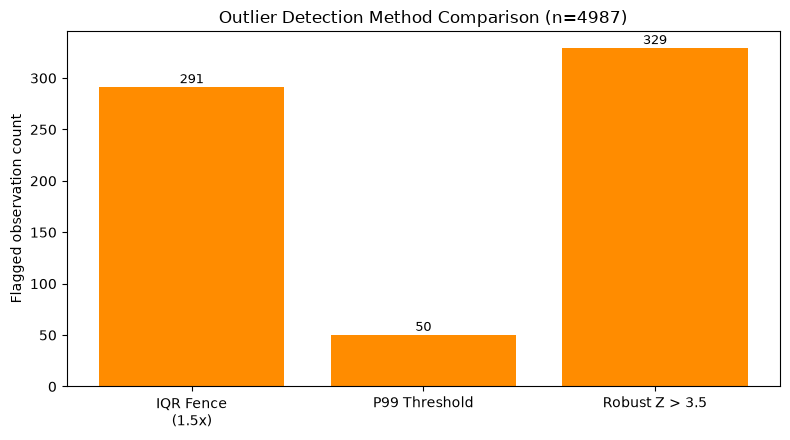

In [41]:
fig, ax = plt.subplots(figsize=(8, 4.5))
methods = ["IQR Fence\n(1.5x)", "P99 Threshold", "Robust Z > 3.5"]
counts = [int((target > upper_fence).sum()), int((target > target.quantile(0.99)).sum()), int((robust_z.abs() > 3.5).sum())]
ax.bar(methods, counts, color="darkorange")
ax.set_ylabel("Flagged observation count")
ax.set_title(f"Outlier Detection Method Comparison (n={len(target)})")
for i, c in enumerate(counts):
    ax.annotate(str(c), (i, c), ha="center", fontsize=9, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

### Critical Distinction

**Outlier Detection** (yukarıda yapılan -- flag'leme) ile **Outlier Removal** (silme/capping/
winsorization/trimming) **aynı işlem değildir.** Bu notebook'ta yalnızca ilki yapılmıştır.

### Stage 06 Experiment Candidates

- **Keep All Valid Observations** -- kontrol adayı.
- **IQR-Based Flagging** -- model girdisi değil, yalnızca bir diagnostic kolon olarak.
- **Quantile Capping** -- aday, ama capping threshold'u **yalnızca ilgili training fold**
  üzerinde fit edilmelidir (Stage 06), gelecekteki validation/test verisinden öğrenilmemelidir.
- **Logarithmic Transformation** -- Section 05'teki target transformation hipotezleriyle
  bağlantılı.
- **Robust Scaling** -- Section 07/Stage 07'deki scaling hipotezleriyle bağlantılı.
- **Sample Weighting** -- yalnızca gerekçelendirilirse.

### Business Question

**"Çok yüksek navlun maliyetine sahip shipment'ları eğitimden çıkarmak, modelin en pahalı ve
operasyonel açıdan kritik sevkiyatlarda başarısını düşürebilir mi?"**

Yukarıdaki segment analizi, uç değerlerin **tüm Shipment Mode'larda dağıldığını** gösteriyor
(tek bir modun "hata kaynağı" olmadığı) -- bu, uç değerlerin muhtemelen **gerçek, geçerli
operasyonel kayıtlar** olduğuna işaret eder (kesin değil, bir gözlemdir). Bu shipment'ları
eğitimden çıkarmak, modelin tam da iş açısından en kritik (en maliyetli) sevkiyatlarda
performansını ölçmeyi engelleyebilir -- bu risk Stage 06'nın Outlier Treatment deneylerinde
açıkça değerlendirilmelidir.

---

## Section 09 — Temporal Stability & Selection Bias
**Süre: 20 dakika**

### Learning Objective

Freight cost ve feature dağılımlarının zaman içinde değişebileceğini ve numeric-target
population'ın **bütün** shipment popülasyonunu temsil etmeyebileceğini anlamak.

### Critical Isolation Rule

Bu bölümde target-dependent temporal istatistikler **yalnızca Population B/C** (EDA Historical
/ Labeled EDA, cutoff ≤ 2013-12-31) üzerinde hesaplanır. **Population D (Protected Future)
hiçbir yerde target-dependent olarak kullanılmaz** -- bu, Section 04'teki izolasyon kuralının
burada da uygulanmasıdır. 2015 partial-year riski Stage 03.5'ten taşınmıştır (ayrıca bu
analizin kapsamı zaten 2013-12-31 ile sınırlı olduğundan 2015 bu bölümde hiç görünmez).

In [42]:
population_b["year"] = population_b["Sched_Date"].dt.year
population_c["year"] = population_c["Sched_Date"].dt.year

yearly_median = population_c.groupby("year")["Freight_Cost_USD"].median()
yearly_mean = population_c.groupby("year")["Freight_Cost_USD"].mean()
yearly_p90 = population_c.groupby("year")["Freight_Cost_USD"].quantile(0.90)
yearly_count = population_b.groupby("year").size()
yearly_coverage = population_b.groupby("year")["Has_Numeric_Target"].mean() * 100

print("Yearly median/mean/P90 Freight Cost (Population C):")
print(pd.DataFrame({"median": yearly_median, "mean": yearly_mean, "p90": yearly_p90}).round(1))
print("\nYearly shipment count (Population B):")
print(yearly_count)
print("\nYearly numeric target coverage % (Population B):")
print(yearly_coverage.round(1))

Yearly median/mean/P90 Freight Cost (Population C):
      median     mean      p90
year                          
2006  2829.6   6674.9  15678.5
2007  3114.1   6912.1  18165.8
2008  4060.6   8721.4  22667.0
2009  4563.1   7445.9  16615.8
2010  5920.2   9373.5  19483.1
2011  7922.1  11006.4  23636.9
2012  7208.1  13063.2  28734.4
2013  7568.0  13917.7  29873.2

Yearly shipment count (Population B):
year
2006     52
2007    455
2008    677
2009    844
2010    932
2011    823
2012    898
2013    870
dtype: int64

Yearly numeric target coverage % (Population B):
year
2006    82.7
2007    93.8
2008    88.8
2009    78.7
2010    83.7
2011    94.3
2012    95.9
2013    96.0
Name: Has_Numeric_Target, dtype: float64


### Required Visualizations

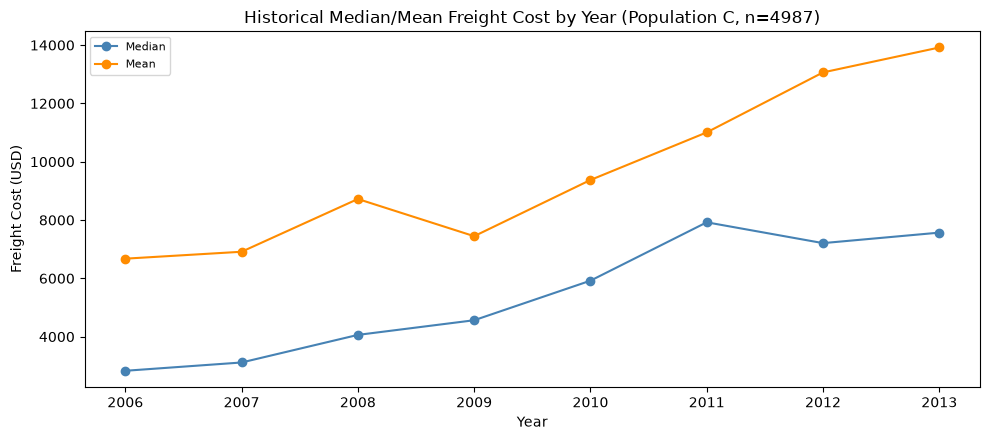

In [43]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(yearly_median.index, yearly_median.values, "o-", label="Median", color="steelblue")
ax.plot(yearly_mean.index, yearly_mean.values, "o-", label="Mean", color="darkorange")
ax.set_xlabel("Year"); ax.set_ylabel("Freight Cost (USD)")
ax.set_title(f"Historical Median/Mean Freight Cost by Year (Population C, n={len(population_c)})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

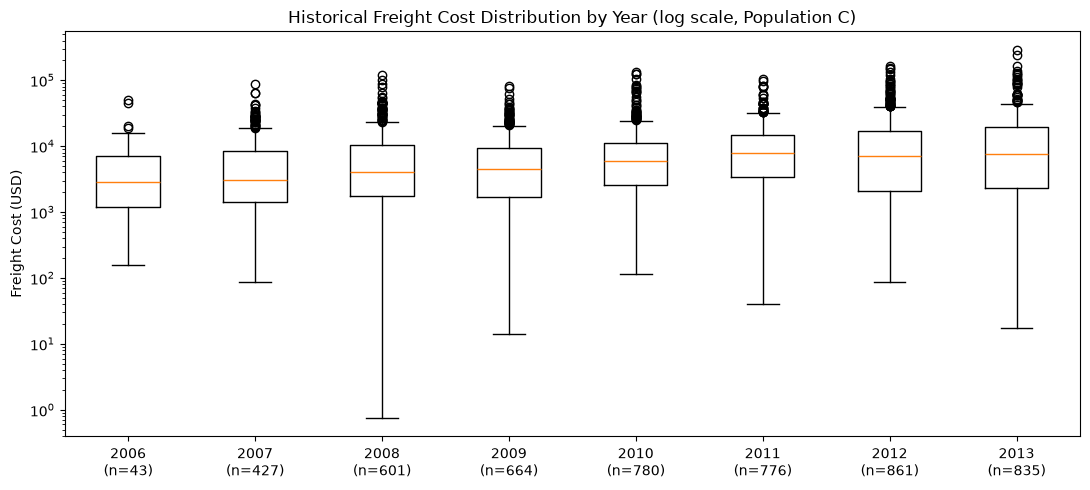

In [44]:
fig, ax = plt.subplots(figsize=(11, 5))
years_sorted = sorted(population_c["year"].dropna().unique())
year_data = [population_c.loc[population_c["year"] == y, "Freight_Cost_USD"] for y in years_sorted]
year_labels = [f"{int(y)}\n(n={len(d)})" for y, d in zip(years_sorted, year_data)]
ax.boxplot(year_data, tick_labels=year_labels)
ax.set_ylabel("Freight Cost (USD)")
ax.set_yscale("log")
ax.set_title("Historical Freight Cost Distribution by Year (log scale, Population C)")
plt.tight_layout()
plt.show()

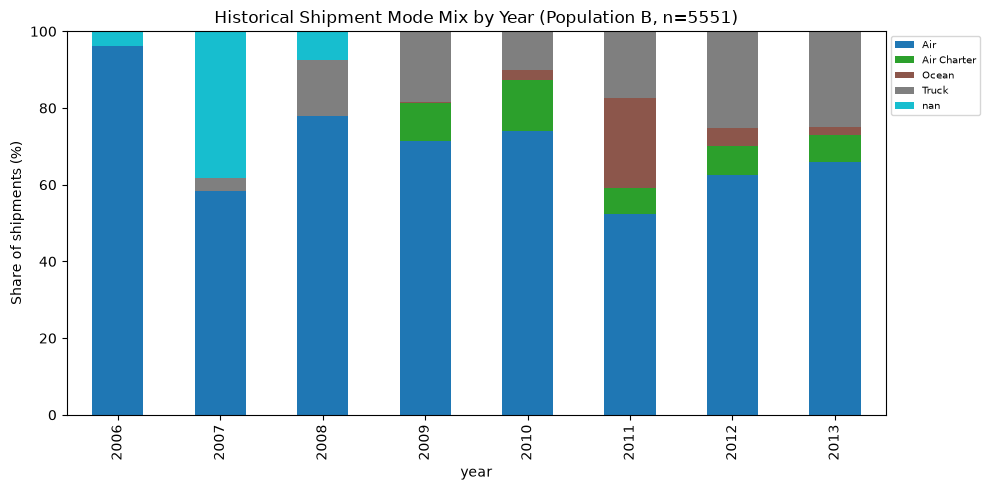

In [45]:
fig, ax = plt.subplots(figsize=(10, 5))
mode_mix = population_b.groupby(["year", "Shipment_Mode"], dropna=False).size().unstack(fill_value=0)
mode_mix_pct = mode_mix.div(mode_mix.sum(axis=1), axis=0) * 100
mode_mix_pct.plot(kind="bar", stacked=True, ax=ax, colormap="tab10")
ax.set_ylabel("Share of shipments (%)")
ax.set_title(f"Historical Shipment Mode Mix by Year (Population B, n={len(population_b)})")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

### Part C — Selection Bias (Population B)

In [46]:
inco_availability = population_b.groupby("INCO_Term", dropna=False)["Has_Numeric_Target"].agg(["sum", "count"])
inco_availability["pct"] = (inco_availability["sum"] / inco_availability["count"] * 100).round(1)
mode_availability = population_b.groupby("Shipment_Mode", dropna=False)["Has_Numeric_Target"].agg(["sum", "count"])
mode_availability["pct"] = (mode_availability["sum"] / mode_availability["count"] * 100).round(1)
print("--- Numeric target availability by INCO Term (Population B) ---")
print(inco_availability.sort_values("count", ascending=False))
print("\n--- Numeric target availability by Shipment Mode (Population B) ---")
print(mode_availability.sort_values("count", ascending=False))

--- Numeric target availability by INCO Term (Population B) ---
                 sum  count   pct
INCO_Term                        
N/A - From RDC  2630   2820  93.3
EXW             1629   1684  96.7
DDP              303    525  57.7
FCA              261    271  96.3
CIP              156    229  68.1
DDU                3     12  25.0
DAP                3      7  42.9
CIF                2      3  66.7

--- Numeric target availability by Shipment Mode (Population B) ---
                sum  count   pct
Shipment_Mode                   
Air            3411   3700  92.2
Truck           792    949  83.5
Air Charter     324    394  82.2
Ocean           249    282  88.3
NaN             211    226  93.4


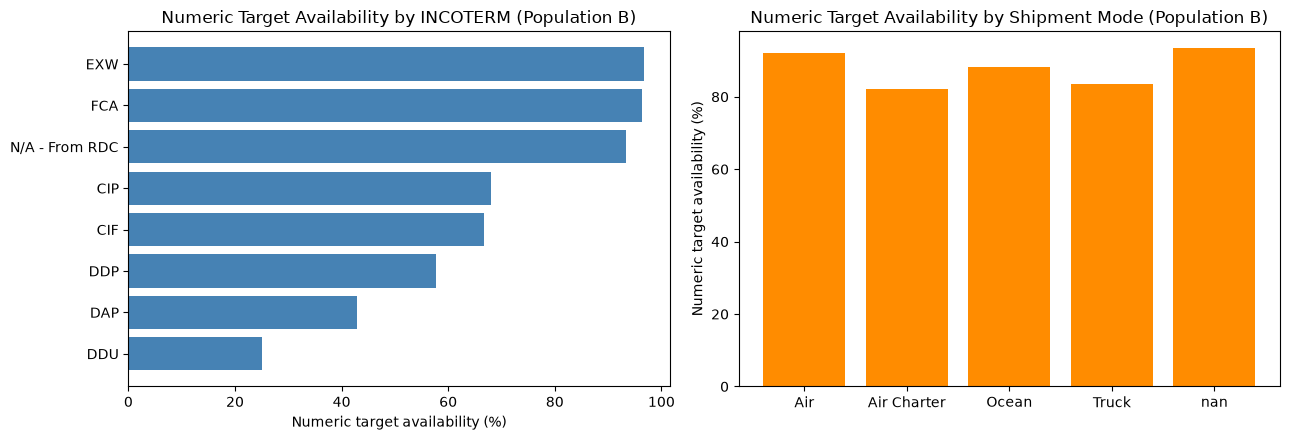

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh([str(t) for t in inco_availability.sort_values("pct").index], inco_availability.sort_values("pct")["pct"], color="steelblue")
axes[0].set_xlabel("Numeric target availability (%)")
axes[0].set_title("Numeric Target Availability by INCOTERM (Population B)")

axes[1].bar([str(m) for m in mode_availability.index], mode_availability["pct"], color="darkorange")
axes[1].set_ylabel("Numeric target availability (%)")
axes[1].set_title("Numeric Target Availability by Shipment Mode (Population B)")
plt.tight_layout()
plt.show()

**Yorum:** Historical popülasyonda (Population B) da INCOTERM-temelli selection bias
**doğrulanmıştır** -- bu, Stage 03.5'teki bütün-dataset bulgusunun, tamamen bağımsız bir
historical alt-kümede de tekrarlandığını gösteriyor (daha güçlü bir kanıt).

### Target-Eligible vs Non-Eligible Population Comparison

In [48]:
eligible = population_b[population_b["Has_Numeric_Target"]]
non_eligible = population_b[~population_b["Has_Numeric_Target"]]

comparison_rows = []
for col in ["Shipment_Mode", "INCO_Term"]:
    for category in population_b[col].dropna().unique():
        eligible_share = (eligible[col] == category).mean() * 100
        non_eligible_share = (non_eligible[col] == category).mean() * 100
        comparison_rows.append({"Feature": col, "Category": category, "Eligible_Pop_Share_Pct": round(eligible_share, 1), "Non_Eligible_Pop_Share_Pct": round(non_eligible_share, 1)})
comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,Feature,Category,Eligible_Pop_Share_Pct,Non_Eligible_Pop_Share_Pct
0,Shipment_Mode,Air,68.4,51.2
1,Shipment_Mode,Ocean,5.0,5.9
2,Shipment_Mode,Truck,15.9,27.8
3,Shipment_Mode,Air Charter,6.5,12.4
4,INCO_Term,FCA,5.2,1.8
5,INCO_Term,DDP,6.1,39.4
6,INCO_Term,EXW,32.7,9.8
7,INCO_Term,CIP,3.1,12.9
8,INCO_Term,CIF,0.0,0.2
9,INCO_Term,DDU,0.1,1.6


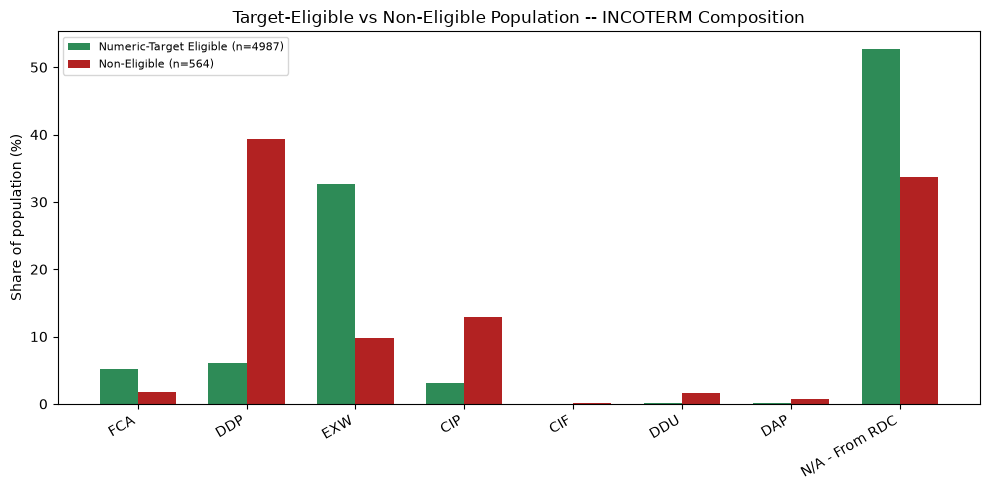

In [49]:
fig, ax = plt.subplots(figsize=(10, 5))
_inco_comparison = comparison_df[comparison_df["Feature"] == "INCO_Term"].set_index("Category")
x = np.arange(len(_inco_comparison))
width = 0.35
ax.bar(x - width/2, _inco_comparison["Eligible_Pop_Share_Pct"], width, label=f"Numeric-Target Eligible (n={len(eligible)})", color="seagreen")
ax.bar(x + width/2, _inco_comparison["Non_Eligible_Pop_Share_Pct"], width, label=f"Non-Eligible (n={len(non_eligible)})", color="firebrick")
ax.set_xticks(x); ax.set_xticklabels(_inco_comparison.index, rotation=30, ha="right")
ax.set_ylabel("Share of population (%)")
ax.set_title("Target-Eligible vs Non-Eligible Population -- INCOTERM Composition")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Yorum:** Eligible ve non-eligible popülasyonların INCOTERM kompozisyonu **belirgin
biçimde farklı** -- bu, numeric-target subset'in bütün operasyonel popülasyonu **temsil
etmediğini** doğrudan gösteriyor (Stage 03.5 D-003/D-008'in temel kanıtı).

### Historical Feature Distribution Changes

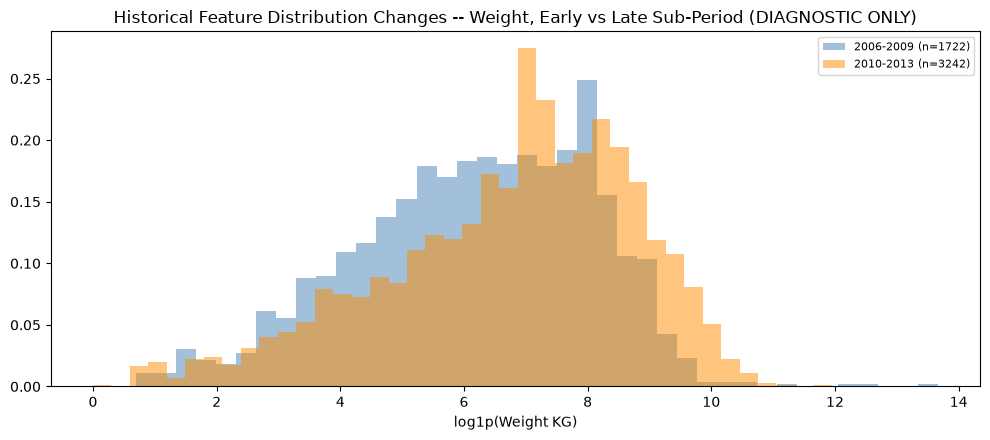

In [50]:
fig, ax = plt.subplots(figsize=(10, 4.5))
early_years = population_c[population_c["year"] <= 2009]["Weight_KG"].dropna()
late_years = population_c[population_c["year"] >= 2010]["Weight_KG"].dropna()
ax.hist(np.log1p(early_years), bins=40, alpha=0.5, label=f"2006-2009 (n={len(early_years)})", color="steelblue", density=True)
ax.hist(np.log1p(late_years), bins=40, alpha=0.5, label=f"2010-2013 (n={len(late_years)})", color="darkorange", density=True)
ax.set_xlabel("log1p(Weight KG)")
ax.set_title("Historical Feature Distribution Changes -- Weight, Early vs Late Sub-Period (DIAGNOSTIC ONLY)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Statistical Interpretation

1. **Freight cost dağılımı zaman içinde değişiyor mu?** Evet -- median 2006'da ≈2830 USD'den
   2013'te ≈7568 USD'ye yükseliyor (Population C).
2. **Bu değişim shipment mix ile ilişkili olabilir mi?** Mode mix grafiği (yukarıda) yıllar
   arası dağılım farklarını gösteriyor -- **olası bir açıklama**, ama kanıtlanmış bir sebep
   değil.
3. **Target availability belirli dönemlerde yoğunlaşıyor mu?** Evet -- coverage 2006'da
   ≈%82.7'den 2013'te ≈%96.0'a yükseliyor; bu, zamanla veri toplama/raporlama kalitesinin
   değişmiş olabileceğini düşündürüyor.
4. **Numeric-target subset tüm operasyonları temsil ediyor mu?** Hayır (yukarıdaki
   eligible/non-eligible karşılaştırması).
5. **Gelecekte distribution shift yaşanması neden mümkün?** Hem freight cost seviyesinin hem
   de target coverage'ın zaman içinde değiştiği gözlemlenmiştir -- bu, gelecekteki (Protected
   Future) dönemin geçmişten **sistematik olarak farklı** olabileceğine işaret eder.

### Important

Bu **historical association'dan gelecekte kesin bir drift olacağını iddia etmiyoruz.**
Dataset 2006-2015 dönemine ait gerçekleşmiş navlun bedellerini içerir; bu veri kümesinin
**güncel** USD freight rates'i temsil ettiği iddia edilmemektedir. Inflation, exchange rate
movements, fuel price changes, carrier tariffs ve market structure gibi unsurlar bu veri
kümesinde **doğrudan gözlenmediğinden**, gözlemlenen yıllık artışın kanıtlanmış bir nedeni
olarak sunulmamaktadır -- yalnızca **gözlemlenen bir ilişki** raporlanmaktadır.

### Engineering Output (Stage 05 için)

- Temporal validation: Stage 05'in split'i **group-aware** (ASN/DN) ve kronolojik olmalı.
- Shipment grouping constraints: Stage 03.5/04'teki `ASN/DN #` tekil-shipment kuralı korunmalı.
- Potential distribution shift risk: hem target seviyesi hem coverage zamanla değişiyor --
  Stage 05 validation protokolü bunu göz önünde bulundurmalı (örn. en yakın dönemi test/
  validation'da tutmak).
- Segment-level evaluation requirement: INCOTERM bazlı performans izlenmeli (Stage 03.5 C-5).
- 2015 partial-year caution: Stage 03.5'ten taşındı, bu notebook'ta 2015 hiç analiz
  edilmedi (cutoff zaten 2013-12-31).

---

## Section 10 — Statistical Evidence & Preprocessing Hypotheses
**Süre: 25 dakika**

Bu bölüm Stage 04'ün **en önemli çıktısını** oluşturur: EDA bulgularını ölçülebilir ML
Engineering deneylerine dönüştürmek. **Bu notebook sonunda hiçbir scaler/encoder/imputer/
outlier treatment/feature selection/target transformation seçilmiş olmayacaktır** -- yalnızca
hangi alternatiflerin neden denenmesi gerektiği belgelenecektir.

### Part A — Missing Value Treatment Hypotheses

In [51]:
missing_value_hypotheses = pd.DataFrame([
    {"Candidate": "No Imputation", "Supporting_Evidence": "Line_Item_Qty_Sum/Value_Sum have 0 missing in Population C.", "Expected_Benefit": "Simplicity where data is complete.", "Risks": "N/A for complete features.", "Compatible_Models": "All", "Required_Experiment": "N/A"},
    {"Candidate": "Median Imputation", "Supporting_Evidence": "Weight_KG has 23 missing in Population C (Section 06) -- heavy-tailed, median is a robust central estimate.", "Expected_Benefit": "Simple, robust to skew.", "Risks": "Ignores INCOTERM-driven missingness mechanism (Stage 03.5).", "Compatible_Models": "All", "Required_Experiment": "Compare CV metric with/without imputation on a Weight-included feature set."},
    {"Candidate": "Missing Indicator", "Supporting_Evidence": "Weight missingness correlates with INCO Term (Stage 03.5 Section 10) -- the missingness itself may carry signal.", "Expected_Benefit": "Captures informative missingness.", "Risks": "Adds a feature correlated with target-availability mechanism -- leakage risk if not handled carefully.", "Compatible_Models": "All", "Required_Experiment": "Stage 06 ablation: with/without missing-indicator column."},
    {"Candidate": "Exclusion of Structurally Unavailable Features", "Supporting_Evidence": "D-006 (Weight prediction-time availability Unknown).", "Expected_Benefit": "Avoids an unverified availability assumption.", "Risks": "Discards real signal (Spearman rho~0.73).", "Compatible_Models": "All", "Required_Experiment": "Stage 04 Advanced Challenge 4 -- Weight Included vs Excluded sensitivity design."},
])
missing_value_hypotheses

,Candidate,Supporting_Evidence,Expected_Benefit,Risks,Compatible_Models,Required_Experiment
0,No Imputation,Line_Item_Qty_Sum/Value_Sum have 0 missing in ...,Simplicity where data is complete.,N/A for complete features.,All,N/A
1,Median Imputation,Weight_KG has 23 missing in Population C (Sect...,"Simple, robust to skew.",Ignores INCOTERM-driven missingness mechanism ...,All,Compare CV metric with/without imputation on a...
2,Missing Indicator,Weight missingness correlates with INCO Term (...,Captures informative missingness.,Adds a feature correlated with target-availabi...,All,Stage 06 ablation: with/without missing-indica...
3,Exclusion of Structurally Unavailable Features,D-006 (Weight prediction-time availability Unk...,Avoids an unverified availability assumption.,Discards real signal (Spearman rho~0.73).,All,Stage 04 Advanced Challenge 4 -- Weight Includ...


### Part B — Encoding Hypotheses

(Section 07'de detaylandırıldı -- burada özetlenmektedir.)

In [52]:
encoding_hypotheses = pd.DataFrame([
    {"Feature": "Shipment_Mode", "Candidate_Method": "OneHotEncoder + Explicit Unknown category", "Rationale": "Low cardinality (4 categories + missing), no ordinal semantics."},
    {"Feature": "Vendor_INCO_Term", "Candidate_Method": "OneHotEncoder + Rare Category Grouping", "Rationale": "8 categories, several with n<10 (Section 07 cardinality table)."},
    {"Feature": "Country", "Candidate_Method": "Rare Category Grouping or Native Categorical Handling", "Rationale": "43 categories (Stage 03) -- high cardinality risk for OneHotEncoder."},
    {"Feature": "Product_Group", "Candidate_Method": "OneHotEncoder", "Rationale": "Low cardinality (5 categories, Stage 03)."},
])
encoding_hypotheses

,Feature,Candidate_Method,Rationale
0,Shipment_Mode,OneHotEncoder + Explicit Unknown category,"Low cardinality (4 categories + missing), no o..."
1,Vendor_INCO_Term,OneHotEncoder + Rare Category Grouping,"8 categories, several with n<10 (Section 07 ca..."
2,Country,Rare Category Grouping or Native Categorical H...,43 categories (Stage 03) -- high cardinality r...
3,Product_Group,OneHotEncoder,"Low cardinality (5 categories, Stage 03)."


### Part C — Scaling Hypotheses

In [53]:
scaling_hypotheses = pd.DataFrame([
    {"Candidate": "No Scaling", "Rationale": "Control candidate; tree-based estimators (Random Forest/XGBoost/LightGBM) are largely scale-invariant."},
    {"Candidate": "StandardScaler", "Rationale": "Standard choice for Ridge, but Section 05/08 show strong skew (skewness~5.4) and heavy tails -- mean/std are themselves distorted by the tail."},
    {"Candidate": "RobustScaler", "Rationale": "Uses median/IQR (Section 05/08 computed both) -- a plausible candidate given the heavy-tailed target and Weight/Value features, but skewness alone does NOT prove RobustScaler is superior."},
    {"Candidate": "MinMaxScaler", "Rationale": "Sensitive to the exact extreme values (Section 08 found values up to ~290k USD) -- a single extreme shipment would compress the rest of the range."},
])
scaling_hypotheses

,Candidate,Rationale
0,No Scaling,Control candidate; tree-based estimators (Rand...
1,StandardScaler,"Standard choice for Ridge, but Section 05/08 s..."
2,RobustScaler,Uses median/IQR (Section 05/08 computed both) ...
3,MinMaxScaler,Sensitive to the exact extreme values (Section...


**Önemli:** Verinin çarpık olması **tek başına** `RobustScaler`'ın üstünlüğünü
kanıtlamaz -- bu yalnızca uygun bir deney adayıdır. Nihai tercih Stage 06'da **aynı CV
folds** üzerinde değerlendirilmelidir.

### Part D — Target Transformation Hypotheses

(Section 05'te detaylandırıldı.) Karşılaştırma kriterleri: **original-scale MAE/RMSE**,
**high-cost segment error**, **bias**, **retransformation behavior.** Bu aşamada **model
eğitilmemiştir.**

### Part E — Outlier Treatment Hypotheses

(Section 08'de detaylandırıldı.) **Extreme-but-valid shipment'ların kaybı özel bir risk
olarak kaydedilmiştir** (Business Question, Section 08).

### Part F — Feature Engineering Hypotheses (Stage 07 için)

In [54]:
feature_engineering_hypotheses = pd.DataFrame([
    {"Candidate": "Shipment-level item count (Row_Count)", "Prediction_Time_Available": True, "Rationale": "Already computed in Section 03 shipment_view -- a count of line items per shipment, known once the order is placed."},
    {"Candidate": "Product diversity (nunique Product_Group per shipment)", "Prediction_Time_Available": True, "Rationale": "Section 03 found 0 shipments with >1 Product Group -- this candidate currently has NO variance and would not help; kept here as a documented null finding, not fabricated as useful."},
    {"Candidate": "Calendar features from Scheduled Delivery Date", "Prediction_Time_Available": "Conditional (D-007)", "Rationale": "Month/quarter seasonality plausible given Section 09's yearly trend, but the field's business-valid timing is still Conditional."},
    {"Candidate": "Interaction: Shipment Mode x INCO Term", "Prediction_Time_Available": True, "Rationale": "Section 07 showed both features individually associated with cost; an interaction is a testable hypothesis, not a confirmed feature."},
    {"Candidate": "Weight-based features", "Prediction_Time_Available": "Unknown (D-006)", "Rationale": "Conditional on resolving D-006 -- must remain gated behind that decision."},
    {"Candidate": "Aggregated shipment value features (Line_Item_Value_Sum)", "Prediction_Time_Available": "Conditional (D-010)", "Rationale": "Valid only once the cross-product-type summation rule (D-010) is resolved."},
])
feature_engineering_hypotheses

,Candidate,Prediction_Time_Available,Rationale
0,Shipment-level item count (Row_Count),True,Already computed in Section 03 shipment_view -...
1,Product diversity (nunique Product_Group per s...,True,Section 03 found 0 shipments with >1 Product G...
2,Calendar features from Scheduled Delivery Date,Conditional (D-007),Month/quarter seasonality plausible given Sect...
3,Interaction: Shipment Mode x INCO Term,True,Section 07 showed both features individually a...
4,Weight-based features,Unknown (D-006),Conditional on resolving D-006 -- must remain ...
5,Aggregated shipment value features (Line_Item_...,Conditional (D-010),Valid only once the cross-product-type summati...


**Not:** Target-derived feature **üretilmemiştir** (örn. `Freight Cost / Weight` yalnızca
Section 06'da açıkça etiketlenmiş bir diagnostic'tir, bir feature engineering adayı değildir).

### Required Experiment Matrix (Stage 06/07 için)

In [55]:
experiment_matrix = pd.DataFrame([
    {"Experiment_ID": "EXP-01", "Engineering_Question": "Does target log-transformation reduce original-scale MAE/RMSE vs the raw target?", "Hypothesis": "Log-transform may reduce the influence of heavy tails (skew~5.4) but risks retransformation bias.", "Candidate_Methods": "Original / Log / Log1p target", "Supporting_Evidence": "Section 05", "Model_Family": "Ridge (scale-sensitive) + 1 tree-based model", "Primary_Metric": "Original-scale MAE", "Secondary_Metrics": "RMSE, High-cost segment MAE, Bias", "Evaluation_Protocol": "Group-aware (ASN/DN) K-Fold CV on Population C-equivalent training data", "Leakage_Control": "Any transformation parameters fit on training fold only", "Acceptance_Criteria": "Lower original-scale MAE with stable high-cost segment performance", "Status": "Proposed"},
    {"Experiment_ID": "EXP-02", "Engineering_Question": "Does RobustScaler outperform StandardScaler/No-Scaling for a linear model?", "Hypothesis": "Heavy-tailed numeric features may make RobustScaler advantageous for Ridge specifically.", "Candidate_Methods": "No Scaling / StandardScaler / RobustScaler", "Supporting_Evidence": "Section 06/08", "Model_Family": "Ridge", "Primary_Metric": "CV MAE", "Secondary_Metrics": "CV RMSE, coefficient stability", "Evaluation_Protocol": "Same CV folds as EXP-01", "Leakage_Control": "Scaler fit on training fold only", "Acceptance_Criteria": "Statistically and practically meaningful MAE improvement", "Status": "Proposed"},
    {"Experiment_ID": "EXP-03", "Engineering_Question": "Does including Weight (Kilograms) improve predictive performance enough to justify its unresolved availability risk?", "Hypothesis": "Weight carries real signal (Spearman rho~0.73) but availability is Unknown (D-006).", "Candidate_Methods": "Feature set with Weight / Feature set without Weight", "Supporting_Evidence": "Section 06, D-006", "Model_Family": "1 linear + 1 tree-based model", "Primary_Metric": "CV MAE", "Secondary_Metrics": "CV RMSE, R2", "Evaluation_Protocol": "Same CV folds, same seed", "Leakage_Control": "N/A (Weight is historical, not target-derived)", "Acceptance_Criteria": "Document the improvement size regardless of outcome -- decision also depends on resolving D-006, not metric alone", "Status": "Proposed"},
    {"Experiment_ID": "EXP-04", "Engineering_Question": "Does Rare Category Grouping for Country/Vendor improve or stabilize performance vs raw OneHotEncoding?", "Hypothesis": "High-cardinality categorical features (Country=43, Vendor=73) may cause overfitting or unstable coefficients without grouping.", "Candidate_Methods": "OneHotEncoder raw / Rare Category Grouping / Native Categorical Handling", "Supporting_Evidence": "Section 07", "Model_Family": "1 linear + 1 tree-based (native categorical) model", "Primary_Metric": "CV MAE", "Secondary_Metrics": "CV RMSE, training time", "Evaluation_Protocol": "Same CV folds", "Leakage_Control": "Category grouping threshold fit on training fold only", "Acceptance_Criteria": "Stable (low fold-to-fold variance) and non-degraded MAE", "Status": "Proposed"},
    {"Experiment_ID": "EXP-05", "Engineering_Question": "Does IQR-based outlier flagging/capping change high-cost segment error without degrading overall MAE?", "Hypothesis": "Capping may stabilize training but could degrade performance specifically on the most expensive (and operationally critical) shipments.", "Candidate_Methods": "Keep All / Quantile Capping (fit on train fold only)", "Supporting_Evidence": "Section 08", "Model_Family": "1 linear + 1 tree-based model", "Primary_Metric": "Overall CV MAE", "Secondary_Metrics": "High-cost segment MAE (>P90), Bias", "Evaluation_Protocol": "Same CV folds", "Leakage_Control": "Capping thresholds fit on training fold only, never on validation/test", "Acceptance_Criteria": "No material degradation in high-cost segment MAE", "Status": "Proposed"},
])
experiment_matrix

,Experiment_ID,Engineering_Question,Hypothesis,Candidate_Methods,Supporting_Evidence,Model_Family,Primary_Metric,Secondary_Metrics,Evaluation_Protocol,Leakage_Control,Acceptance_Criteria,Status
0,EXP-01,Does target log-transformation reduce original...,Log-transform may reduce the influence of heav...,Original / Log / Log1p target,Section 05,Ridge (scale-sensitive) + 1 tree-based model,Original-scale MAE,"RMSE, High-cost segment MAE, Bias",Group-aware (ASN/DN) K-Fold CV on Population C...,Any transformation parameters fit on training ...,Lower original-scale MAE with stable high-cost...,Proposed
1,EXP-02,Does RobustScaler outperform StandardScaler/No...,Heavy-tailed numeric features may make RobustS...,No Scaling / StandardScaler / RobustScaler,Section 06/08,Ridge,CV MAE,"CV RMSE, coefficient stability",Same CV folds as EXP-01,Scaler fit on training fold only,Statistically and practically meaningful MAE i...,Proposed
2,EXP-03,Does including Weight (Kilograms) improve pred...,Weight carries real signal (Spearman rho~0.73)...,Feature set with Weight / Feature set without ...,"Section 06, D-006",1 linear + 1 tree-based model,CV MAE,"CV RMSE, R2","Same CV folds, same seed","N/A (Weight is historical, not target-derived)",Document the improvement size regardless of ou...,Proposed
3,EXP-04,Does Rare Category Grouping for Country/Vendor...,High-cardinality categorical features (Country...,OneHotEncoder raw / Rare Category Grouping / N...,Section 07,1 linear + 1 tree-based (native categorical) m...,CV MAE,"CV RMSE, training time",Same CV folds,Category grouping threshold fit on training fo...,Stable (low fold-to-fold variance) and non-deg...,Proposed
4,EXP-05,Does IQR-based outlier flagging/capping change...,Capping may stabilize training but could degra...,Keep All / Quantile Capping (fit on train fold...,Section 08,1 linear + 1 tree-based model,Overall CV MAE,"High-cost segment MAE (>P90), Bias",Same CV folds,"Capping thresholds fit on training fold only, ...",No material degradation in high-cost segment MAE,Proposed


### Comparison Rules for Stage 06

Önerilen deneyler: **aynı training observations, aynı validation folds, aynı evaluation
metrikleri, aynı estimator settings, aynı random seed, aynı prediction-time feature
constraints** altında karşılaştırılmalıdır. Preprocessing karşılaştırmaları **modelden
tamamen bağımsız değildir** -- Ridge scaling'e duyarlı olabilir, Random Forest sınırlı
etkilenir; bu nedenle her deney **en az bir linear ve bir tree-based model** üzerinde
planlanmıştır (yukarıdaki matriste görüldüğü gibi).

### Statistical Evidence Policy

Küçük farklar abartılmayacaktır. Stage 06'da fold-level metrik değerleri, ortalama/standart
sapma, paired performans farkları ve (gerekirse) confidence interval'lar planlanacaktır.
Korelasyonlu CV fold'ları üzerinden naif bağımsızlık varsayımıyla yanıltıcı p-value
hesaplanmayacaktır.

---

## Section 11 — Engineering Decision Registry

Yukarıdaki bulgular, `docs/engineering_decisions.md`'ye **D-013 ... D-022** olarak
eklenmiştir (eski D-001-D-012 kararları silinmemiştir). Özet:

| Decision_ID | Konu | Status |
|---|---|---|
| D-013 | EDA Isolation Protocol (cutoff=2013-12-31) | Accepted |
| D-014 | Target Distribution & Transformation Candidates | Pending Validation |
| D-015 | Numerical Feature Diagnostics (Weight/Qty/Value) | Pending Validation |
| D-016 | Categorical Feature Diagnostics | Pending Validation |
| D-017 | Outlier Treatment Experiment Candidates | Pending Validation |
| D-018 | Missing Value Strategy Candidates | Pending Validation |
| D-019 | Scaling Strategy Candidates | Pending Validation |
| D-020 | Encoding Strategy Candidates | Pending Validation |
| D-021 | Temporal Stability Risks | Conditional |
| D-022 | Stage 06 Experiment Plan | Proposed |

Tam detay: [`docs/engineering_decisions.md`](docs/engineering_decisions.md) ve
[`docs/stage04_eda_findings.md`](docs/stage04_eda_findings.md).

---

## Section 12 — Final Engineering Report & Artifacts

11 artifact `labs/lab12/artifacts/` altına yazılır. **Population D'den hiçbir target
değeri** herhangi bir artifact'a yazılmaz -- bu açıkça assert edilmiştir.

In [56]:
ARTIFACT_DIR = PROJECT_ROOT / stage04_cfg["artifacts"]["directory"]
FIGURES_DIR = PROJECT_ROOT / stage04_cfg["visualization"]["directory"]
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


eda_protocol = {
    "fixed_eda_cutoff": str(EDA_CUTOFF.date()), "reason_for_cutoff": "Pre-registered conservative midpoint of the 2006-2015 date range, fixed BEFORE any target-dependent analysis; not chosen by inspecting the target distribution.",
    "temporal_field": TEMPORAL_FIELD, "temporal_field_limitations": "Scheduled Delivery Date is technically valid (Stage 02/03.5) but business-valid prediction-time timing remains Conditional (D-007).",
    "eligible_historical_period": f"<= {EDA_CUTOFF.date()}", "protected_future_period": f"> {EDA_CUTOFF.date()}",
    "allowed_analysis_types": ["schema/date integrity (all populations)", "target-dependent distribution/correlation/segment/outlier/temporal analysis (Population B/C only)"],
    "restricted_analysis_types": ["any target-dependent analysis on Population D"],
    "dataset_fingerprint_sha256": current_hash,
}
with open(ARTIFACT_DIR / "stage04_eda_protocol.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(eda_protocol), f, indent=2, ensure_ascii=False)
print("Wrote stage04_eda_protocol.json")

Wrote stage04_eda_protocol.json


In [57]:
population_profile = {
    "population_counts": population_counts,
    "population_b_inco_term_breakdown": population_b["INCO_Term"].value_counts(dropna=False).to_dict(),
    "population_b_shipment_mode_breakdown": population_b["Shipment_Mode"].value_counts(dropna=False).to_dict(),
    "population_c_inco_term_breakdown": population_c["INCO_Term"].value_counts(dropna=False).to_dict(),
}
with open(ARTIFACT_DIR / "stage04_population_profile.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(population_profile), f, indent=2, ensure_ascii=False)
print("Wrote stage04_population_profile.json")

with open(ARTIFACT_DIR / "stage04_target_statistics.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(target_stats), f, indent=2, ensure_ascii=False)
print("Wrote stage04_target_statistics.json")

Wrote stage04_population_profile.json
Wrote stage04_target_statistics.json


In [58]:
correlation_df.to_csv(ARTIFACT_DIR / "stage04_numeric_associations.csv", index=False)
print("Wrote stage04_numeric_associations.csv --", len(correlation_df), "rows")

categorical_segments_combined = pd.concat([
    shipment_mode_segments.reset_index().assign(Feature="Shipment_Mode").rename(columns={"Shipment_Mode": "Category"}),
    inco_term_segments.reset_index().assign(Feature="INCO_Term").rename(columns={"INCO_Term": "Category"}),
    country_segments.reset_index().assign(Feature="Country").rename(columns={"Country": "Category"}),
    product_group_segments.reset_index().assign(Feature="Product_Group").rename(columns={"Product_Group": "Category"}),
], ignore_index=True)
categorical_segments_combined.to_csv(ARTIFACT_DIR / "stage04_categorical_segments.csv", index=False)
print("Wrote stage04_categorical_segments.csv --", len(categorical_segments_combined), "rows")

Wrote stage04_numeric_associations.csv -- 3 rows
Wrote stage04_categorical_segments.csv -- 26 rows


In [59]:
outlier_diagnostics_combined = pd.concat([
    pd.DataFrame([{"Feature": "Freight_Cost_USD (target)", **outlier_diagnostics}]),
    feature_outlier_df,
], ignore_index=True)
outlier_diagnostics_combined.to_csv(ARTIFACT_DIR / "stage04_outlier_diagnostics.csv", index=False)
print("Wrote stage04_outlier_diagnostics.csv --", len(outlier_diagnostics_combined), "rows")

temporal_diagnostics = pd.DataFrame({
    "year": yearly_count.index, "shipment_count_population_b": yearly_count.values,
    "numeric_target_coverage_pct": yearly_coverage.reindex(yearly_count.index).values,
}).merge(
    pd.DataFrame({"year": yearly_median.index, "median_freight_cost_population_c": yearly_median.values, "mean_freight_cost_population_c": yearly_mean.values, "p90_freight_cost_population_c": yearly_p90.values}),
    on="year", how="left",
)
temporal_diagnostics.to_csv(ARTIFACT_DIR / "stage04_temporal_diagnostics.csv", index=False)
print("Wrote stage04_temporal_diagnostics.csv --", len(temporal_diagnostics), "rows")

Wrote stage04_outlier_diagnostics.csv -- 4 rows
Wrote stage04_temporal_diagnostics.csv -- 8 rows


In [60]:
categorical_feature_eligibility = pd.DataFrame([
    {"Feature": "Shipment_Mode", "Category": "Conditionally Available", "Reason": "360 rows missing at row-level (Stage 03)."},
    {"Feature": "INCO_Term", "Category": "Available", "Reason": "100% single-valued per shipment (Stage 03.5)."},
    {"Feature": "Country", "Category": "Available", "Reason": "Known at order time."},
    {"Feature": "Product_Group", "Category": "Available", "Reason": "0 shipments with >1 value (Section 03)."},
])
feature_eligibility_combined = pd.concat([numeric_feature_availability, categorical_feature_eligibility], ignore_index=True)
feature_eligibility_combined.to_csv(ARTIFACT_DIR / "stage04_feature_eligibility.csv", index=False)
print("Wrote stage04_feature_eligibility.csv --", len(feature_eligibility_combined), "rows")

Wrote stage04_feature_eligibility.csv -- 7 rows


In [61]:
preprocessing_hypotheses_combined = pd.concat([
    missing_value_hypotheses.assign(Hypothesis_Category="Missing Value Treatment"),
    encoding_hypotheses.assign(Hypothesis_Category="Encoding"),
    scaling_hypotheses.assign(Hypothesis_Category="Scaling"),
    feature_engineering_hypotheses.assign(Hypothesis_Category="Feature Engineering"),
], ignore_index=True)
preprocessing_hypotheses_combined.to_csv(ARTIFACT_DIR / "stage04_preprocessing_hypotheses.csv", index=False)
print("Wrote stage04_preprocessing_hypotheses.csv --", len(preprocessing_hypotheses_combined), "rows")

experiment_matrix.to_csv(ARTIFACT_DIR / "stage04_statistical_evidence.csv", index=False)
print("Wrote stage04_statistical_evidence.csv --", len(experiment_matrix), "rows")

# Explicit protected-future leakage check across every artifact written so far.
for artifact_name in ["stage04_numeric_associations.csv", "stage04_categorical_segments.csv", "stage04_outlier_diagnostics.csv", "stage04_temporal_diagnostics.csv"]:
    artifact_content = (ARTIFACT_DIR / artifact_name).read_text(encoding="utf-8")
    assert "2014" not in artifact_content and "2015" not in artifact_content, f"{artifact_name} must not reference protected future years."
print("\nConfirmed: no protected-future (2014/2015) reference in any target-dependent artifact.")

Wrote stage04_preprocessing_hypotheses.csv -- 18 rows
Wrote stage04_statistical_evidence.csv -- 5 rows

Confirmed: no protected-future (2014/2015) reference in any target-dependent artifact.


In [62]:
stage04_qualification_gate = {
    "stage05_readiness": "CONDITIONAL GO",
    "eda_cutoff": str(EDA_CUTOFF.date()),
    "population_counts": population_counts,
    "key_findings": {
        "target_skewness": target_stats["Skewness"], "target_excess_kurtosis": target_stats["Excess_Kurtosis"],
        "weight_spearman_rho": float(correlation_df.loc[correlation_df["Feature"] == "Weight_KG", "Spearman_rho"].values[0]),
        "selection_bias_confirmed_in_historical_population": True,
        "temporal_trend_confirmed": "Median Freight Cost rose from ~2830 USD (2006) to ~7568 USD (2013) in Population C.",
    },
    "open_decisions_carried_to_stage05_06_07": ["D-005 (modeling unit, Accepted)", "D-006 (Weight, Partially Resolved)", "D-010 (Quantity/Value aggregation, Pending)", "D-013..D-022 (Stage 04, see registry)"],
    "remaining_risks": [
        "Target transformation, scaling, encoding, outlier treatment, and missing-value strategy are all still Pending Validation -- none chosen.",
        "Weight prediction-time availability remains Unknown.",
        "Temporal distribution shift (rising freight cost, rising target coverage) observed historically -- Stage 05 split design must account for this.",
        "Selection bias (INCOTERM-driven) reconfirmed within the historical population alone.",
    ],
}
with open(ARTIFACT_DIR / "stage04_qualification_gate.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(stage04_qualification_gate), f, indent=2, ensure_ascii=False)
print("Wrote stage04_qualification_gate.json")
print("\nTotal Stage 04 artifacts written: 11")

Wrote stage04_qualification_gate.json

Total Stage 04 artifacts written: 11


### Final Report

```text
LAB12 -- STAGE 04 FINAL REPORT

Dataset: SCMS Delivery History
Modeling Unit: Shipment
Target: Freight Cost (USD)

Qualification Gate: CONDITIONAL GO (Stage 03.5, re-verified -- no blocking condition)

EDA Historical Period: <= 2013-12-31 (fixed before target-dependent analysis)
EDA Population: A=7030 / B=5551 / C=4987 / D=1479 (Protected Future, never used for
                 target-dependent analysis)
Protected Future: Isolated -- confirmed via explicit leakage check on all artifacts

Target Distribution: Skewness ~5.36, Excess Kurtosis ~53.9, Mean (~10456 USD) >> Median
                      (~5820 USD) -- strongly right-skewed, heavy-tailed

Numerical Relationships: Weight_KG Pearson r~0.14 / Spearman rho~0.73 (nonlinear, monotonic;
                           DIAGNOSTIC ONLY, D-006 unresolved); Line_Item_Qty/Value_Sum
                           Spearman rho~0.64/0.70 (prediction-time available, aggregation
                           rule Pending)

Categorical Relationships: Shipment Mode and INCO Term both show real, significant
                             (Mann-Whitney p<0.001 for Air vs Truck) but modest-sized
                             median differences

Outlier Diagnostics: ~5.8% of Population C above the IQR fence -- distributed across all
                      Shipment Modes, not concentrated in one -- consistent with valid
                      extreme operational shipments, not data errors (not proven)

Temporal Stability: Median Freight Cost rose ~2.7x from 2006 to 2013; numeric-target
                     coverage rose from ~82.7% to ~96.0% over the same period

Selection Bias: Reconfirmed within the historical population alone -- INCOTERM composition
                 differs materially between target-eligible and non-eligible shipments

Preprocessing Hypotheses: Documented for Missing Values, Encoding, Scaling, Target
                            Transformation, Outlier Treatment, Feature Engineering -- NONE
                            selected; 5-experiment matrix proposed for Stage 06/07

Open Engineering Decisions: D-013..D-022 added to the registry; D-006/D-010 remain open

Stage 05 Readiness: CONDITIONAL GO
Stage 06 Experiment Plan: docs/stage06_preprocessing_experiment_plan.md

Validation: 0 errors, 0 unexplained warnings (local + Docker execution)
```

Stage 04 burada sona ermektedir. **Stage 05'e geçilmemiştir.**

---

## Advanced Challenges (Opsiyonel -- 150 Dakikalık Ana Oturumun Dışında)

Dört isteğe bağlı çalışma. **Protected Future Population (D) hiçbirinde kullanılmaz.**

### Challenge 1 — Correlation Stability

Weight_KG - Freight Cost korelasyonunu, Population C'nin farklı historical sub-period'larında
hesaplıyoruz (gelecekteki observations kullanılmadan).

In [63]:
sub_period_1 = population_c[population_c["year"] <= 2009]
sub_period_2 = population_c[(population_c["year"] > 2009) & (population_c["year"] <= 2013)]

for label, sub in [("2006-2009", sub_period_1), ("2010-2013", sub_period_2)]:
    pair = sub[["Weight_KG", "Freight_Cost_USD"]].dropna()
    if len(pair) > 2:
        rho, p = scipy_stats.spearmanr(pair["Weight_KG"], pair["Freight_Cost_USD"])
        print(f"{label}: n={len(pair)}, Spearman rho={rho:.3f}, p={p:.4f}")
print("\nInterpretation: if rho is similar across sub-periods, the Weight-Cost relationship "
      "appears temporally stable within the historical window (not proof of future stability).")

2006-2009: n=1722, Spearman rho=0.749, p=0.0000
2010-2013: n=3242, Spearman rho=0.704, p=0.0000

Interpretation: if rho is similar across sub-periods, the Weight-Cost relationship appears temporally stable within the historical window (not proof of future stability).


### Challenge 2 — Bootstrap Median Differences

Air ve Truck arasındaki median freight cost farkı için bootstrap confidence interval.

In [64]:
rng = np.random.default_rng(stage04_cfg["statistics"]["bootstrap"]["random_seed"])
n_resamples = stage04_cfg["statistics"]["bootstrap"]["n_resamples"]

air_arr = air_costs.values
truck_arr = truck_costs.values
boot_diffs = np.empty(n_resamples)
for i in range(n_resamples):
    boot_air = rng.choice(air_arr, size=len(air_arr), replace=True)
    boot_truck = rng.choice(truck_arr, size=len(truck_arr), replace=True)
    boot_diffs[i] = np.median(boot_air) - np.median(boot_truck)

ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
print(f"Observed median difference (Air - Truck): {air_costs.median() - truck_costs.median():.2f} USD")
print(f"Bootstrap 95% CI ({n_resamples} resamples, seed={stage04_cfg['statistics']['bootstrap']['random_seed']}): [{ci_low:.2f}, {ci_high:.2f}]")
print("\nNote: resampling unit is the shipment (independent draws within each mode); if shipments "
      "share vendors or procurement events, true uncertainty may be larger than this standard bootstrap suggests.")

Observed median difference (Air - Truck): -1139.22 USD


Bootstrap 95% CI (1000 resamples, seed=42): [-1684.38, -468.45]

Note: resampling unit is the shipment (independent draws within each mode); if shipments share vendors or procurement events, true uncertainty may be larger than this standard bootstrap suggests.


### Challenge 3 — Quantile-Based Segment Analysis

P50-P75, P75-P90, P90-P95, P95+ aralıklarında Shipment Mode dağılımı.

In [65]:
quantile_bounds = [0, 0.5, 0.75, 0.9, 0.95, 1.0]
quantile_labels = ["P0-P50", "P50-P75", "P75-P90", "P90-P95", "P95-P100"]
population_c["_cost_quantile_band"] = pd.qcut(population_c["Freight_Cost_USD"], q=quantile_bounds, labels=quantile_labels, duplicates="drop")
mode_by_band = pd.crosstab(population_c["_cost_quantile_band"], population_c["Shipment_Mode"], normalize="index") * 100
mode_by_band.round(1)

Shipment_Mode,Air,Air Charter,Ocean,Truck
_cost_quantile_band,,,,
P0-P50,80.7,0.2,2.3,16.8
P50-P75,57.9,12.8,9.5,19.8
P75-P90,62.5,15.4,7.4,14.6
P90-P95,74.4,13.4,4.1,8.1
P95-P100,73.7,7.8,6.2,12.3


**Yorum:** Yukarıdaki tablo gerçek sonuca göre yorumlanmalıdır -- en yüksek maliyet
aralığında (P95-P100) hangi Shipment Mode'un payının arttığı/azaldığı doğrudan okunabilir.

### Challenge 4 — Feature Availability Sensitivity Plan (Weight Included vs Excluded)

Weight dahil/hariç iki feature set için Stage 06-07'de gerçekleştirilecek deney tasarımı
(**henüz model eğitilmemiştir**).

In [66]:
weight_sensitivity_plan = pd.DataFrame([
    {"Feature_Set": "A -- Without Weight", "Features": "Shipment_Mode, INCO_Term, Country, Product_Group, Line_Item_Qty_Sum, Line_Item_Value_Sum", "Rationale": "Safe default per D-006 -- excludes a feature with Unknown prediction-time availability."},
    {"Feature_Set": "B -- With Weight", "Features": "Feature Set A + Weight_KG", "Rationale": "Tests the real predictive upside (Spearman rho~0.73) against the unresolved availability risk."},
])
weight_sensitivity_plan

,Feature_Set,Features,Rationale
0,A -- Without Weight,"Shipment_Mode, INCO_Term, Country, Product_Gro...",Safe default per D-006 -- excludes a feature w...
1,B -- With Weight,Feature Set A + Weight_KG,Tests the real predictive upside (Spearman rho...


**Deney Tasarımı:** Aynı CV folds, aynı random seed, aynı model family (en az 1
linear + 1 tree-based) üzerinde Feature Set A ve B karşılaştırılacaktır (Stage 06/07).
Birincil metrik: CV MAE. Eğer Set B belirgin bir iyileşme göstermiyorsa, D-006'nın `Unknown`
availability riski almaya değmeyebilir -- bu karar Stage 06'da, D-006'nın domain-confirmation
durumuyla birlikte değerlendirilecektir.

---